# Analysing the variant allele frequencies of SNPs in the three chromosomal regions of interest

## Import libraries

In [92]:
library(readr)
library(dplyr)
library(stringr)
library(readxl)
library(ggplot2)
library(jtools)
library(patchwork) 
library(GenomicRanges)
library(rtracklayer)

## Options

In [10]:
options(scipen=999)

## Load clade groupings

In [11]:
# Load clone information
groups <- data.frame(read_csv("../Data/CNA_Data/Processed/GeneticCladeGroupings_DifferentialATACSignalAnalysis.csv",
                              col_types = "cccd"))

groups <- na.omit(groups)
groups <- groups %>% filter(!Location %in% c("chr7:500001-46000000","chr11:48000001-134500000")) %>%
  mutate("Location_True" = case_when(Location == "chr1:162000001-175000000" ~ "chr1:161-174.5Mb",
                                     Location == "chr5:49500001-92500000" ~ "chr5:46.5-93Mb",
                                     Location == "chr18:1000001-13500000" ~ "chr18:0-19Mb",
                                     Location == "chr20:500001-19500000" ~ "chr20:0-17.5Mb",
                                     Location == "chrX:500001-53500000" ~ "chrX:0-57Mb"))   # Used the non-segmented data to obtain conservative estimates of "true" breakpoint locations

# load clades to get cell ids
clades <- read_csv("../Data/CNA_Data/Processed/Genetic_Clades_And_SuperClades.csv",
                              col_types = "ccc")
rownames(clades) <- clades$Cell_id

Warning message:
“Setting row names on a tibble is deprecated.”


## Import SNP matrix - WGS data

In [12]:
wgs_snp <- data.frame(read_csv("../Data/SNP_Data/WGS/DATAC_WGS_hg19_matrix.csv"))

# format the cell ids
colnames(wgs_snp) <- colnames(wgs_snp) %>% str_replace(".SW620bc_DT1_P1a","") %>% 
  str_replace(".SW620bc_DT1_P1b","") %>%
  str_replace(".SW620bc_DSIVb","") %>%
  str_replace(".SW620bc_DSIVa","") %>%
  str_replace(".SW620bc_POTa","") %>%
  str_replace(".SW620bc_DSIb","") %>%
  str_replace(".SW620_POTb","") %>%
  str_replace(".SW620_DSIa","")

Rows: 321821 Columns: 2305
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (1): SNP_ID
dbl (2304): SW620bc_DSIVa_L_DATAC_A1-SW620bc_DSIVa, SW620bc_DSIVa_L_DATAC_A1...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Import SNP matrix - ATAC data 

In [13]:
atac_snp <- data.frame(read_csv("../Data/SNP_Data/ATAC/DATAC_ATAC_hg19_matrix_relabeled.csv"))

# Format the cell ids
colnames(atac_snp) <- gsub("_SW620bc_.*","",colnames(atac_snp))  %>% str_replace(".SW620bc_DT1_P1a","") %>% 
  str_replace(".SW620bc_DT1_P1b","") %>%
  str_replace(".SW620bc_DSIVb","") %>%
  str_replace(".SW620bc_DSIVa","") %>%
  str_replace(".SW620bc_POTa","") %>%
  str_replace(".SW620bc_DSIb","") %>%
  str_replace(".SW620_POTb","") %>%
  str_replace(".SW620_DSIa","")

# Filter for the cells of interest
atac_snp_fil <- atac_snp[,colnames(atac_snp) %in% c("SNP_ID",colnames(wgs_snp))] 

Rows: 159376 Columns: 2252
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (1): SNP_ID
dbl (2251): SW620bc_DSIVa_L_DATAC_A10-SW620bc_DSIVa, SW620bc_DSIVa_L_DATAC_A...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Gain in chromosome 5

### WGS: Identify heterozygous SNPs

In [14]:
# Select for the SNPs on chromosome 5
wgs_snp_5 <- data.frame(wgs_snp[grep("5_[0-9]+_[A-Z]_[A_Z]",wgs_snp$SNP_ID),])
rownames(wgs_snp_5) <- wgs_snp_5$SNP_ID

# Identify the heterozygous SNPs using the cells which have copy number 3 for
# 1-46.5Mb and copy number 2 otherwise

# Select for those cells
wgs_snp_5_dip <- wgs_snp_5[,colnames(wgs_snp_5) %in% c("SNP_ID",
                                                       clades[clades$Clade %in% groups[groups$Location == "chr5:49500001-92500000" & groups$Altered == "0",]$Clade,]$Cell_id)] 

# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
wgs_snp_5_dip <- wgs_snp_5_dip %>% dplyr::mutate(Present = rowSums(across(everything(), ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(everything(), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(everything(), ~ .x == -1)))

counts_5_dip <- wgs_snp_5_dip[,c("SNP_ID","Present","Absent","NA")]

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_5_dip <- counts_5_dip %>% dplyr::mutate(VariantFreq =100*(Present/(Absent + Present))) %>% 
  dplyr::mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(unlist(str_split(counts_5_dip$SNP_ID,"_"))[seq(2,nrow(counts_5_dip)*4,4)])) %>%
  mutate(Region = case_when(Location <= 46500000 ~ "Shared gain",
                            (Location > 46500000 & Location <= 93000000) ~ "Gain in G1",
                            Location > 93000000 ~ "Diploid")) 


# Save the SNP info
write_csv(counts_5_dip, "../Data/SNP_Data/WGS/Chr5/Chr5_WGS_AllSNPs_Info.csv")

# Filter for heterozygous SNPs, which have at least 10 support reads 
# (i.e., 10 cells with the SNP)
counts_5_het <- counts_5_dip %>% filter((Location >= 46500000 & VariantFreq >= 40 & VariantFreq <= 60) |
                                          ( Location < 46500000 & VariantFreq >= 23 & VariantFreq <= 43) |
                                          ( Location < 46500000 & VariantFreq >= 56 & VariantFreq <= 76)) %>%
  filter(Present >= 10)

# heterozygous SNP ids
counts_5_het_snps <- counts_5_het$SNP_ID

# Save the heterozygous SNP info
write_csv(counts_5_het, "../Data/SNP_Data/WGS/Chr5/Chr5_WGS_HetSNPs_Info.csv")

### WGS: Compute and compare the heterozygous SNP frequencies in the two copy number clones

In [17]:
# Filter the SNP matrix to include cells in G0 and G1 
wgs_snp_5_cc0 <- wgs_snp_5[rownames(wgs_snp_5) %in% counts_5_het_snps,
                           colnames(wgs_snp_5) %in% c("SNP_ID", clades[clades$Clade %in% groups[groups$Location == "chr5:49500001-92500000" & groups$Altered == "0",]$Clade,]$Cell_id)]
wgs_snp_5_cc1 <- wgs_snp_5[rownames(wgs_snp_5) %in% counts_5_het_snps,
                           colnames(wgs_snp_5) %in% c("SNP_ID", clades[clades$Clade %in% groups[groups$Location == "chr5:49500001-92500000" & groups$Altered == "1",]$Clade,]$Cell_id)]


# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
wgs_snp_5_cc0 <- wgs_snp_5_cc0 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

wgs_snp_5_cc1 <- wgs_snp_5_cc1 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_c0 <- wgs_snp_5_cc0[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  dplyr::mutate(NonNACount = (Absent + Present)) %>%
  dplyr::mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  dplyr::mutate(Clone = "G0") %>% dplyr::mutate(Mode = "WGS") %>% 
  mutate(Region = case_when(Location <= 46500000 ~ "Shared gain",
                            (Location > 46500000 & Location <= 93000000) ~ "Gain in G1",
                            Location > 93000000 ~ "Diploid"))

counts_c1 <- wgs_snp_5_cc1[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  dplyr::mutate(NonNACount = (Absent + Present)) %>%
  dplyr::mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  dplyr::mutate(Clone = "G1") %>% dplyr::mutate(Mode = "WGS") %>% 
  mutate(Region = case_when(Location <= 46500000 ~ "Shared gain",
                            (Location > 46500000 & Location <= 93000000) ~ "Gain in G1",
                            Location > 93000000 ~ "Diploid"))


# Filter for SNPs with at least 2 reads per allele (on average)
counts_c0 <- counts_c0 %>%
  filter((Region == "Shared gain" & NonNACount >= 6) |
           (Region == "Gain in G1"& NonNACount >= 4) |
           (Region == "Diploid" & NonNACount >= 4)  )
counts_c1 <- counts_c1 %>%
  filter((Region == "Shared gain" & NonNACount >= 6) |
           (Region == "Gain in G1" & NonNACount >= 6) |
           (Region == "Diploid" & NonNACount >= 4)  )


# Define whether SNPs are in open or closed chromatin 
# (based on ATAC signal in peaks computed for each clone)
# Peaks with positions defined in hg38
peaks_hg38 <- read_csv("../Data/ATAC_Data/PeakData/Chr5/Chr5Gain_PeakInformation.csv", col_types = "ccddccc")

# Create a text file with the peak position for liftover
loc <- noquote(sprintf("%s:%s-%s",peaks_hg38$chrom,peaks_hg38$start,peaks_hg38$end))
write.table(loc,"../Data/ATAC_Data/PeakData/Chr5/Chr5Gain_PeakLocationsForLiftOver.txt",
            row.names = F,
            col.names = F,
            quote =F)

# Perform liftover in UCSC Genome Browser (https://genome.ucsc.edu/cgi-bin/hgLiftOver)

# Read in the peak positions defined in hg19 by the liftover  
peaks_hg19_loc <- data.frame(read.table("../Data/ATAC_Data/PeakData/Chr5/Chr5Gain_PeakLocationsForLiftOver_LiftOver.bed",
                                        header = FALSE,
                                        sep="\t",
                                        stringsAsFactors=FALSE, quote=""))


# Format the peak positions in hg19 
peaks_hg19_loc_new <- c()
for (i in 1:nrow(peaks_hg19_loc)){
  peaks_hg19_loc_new <- rbind(peaks_hg19_loc_new,str_split(peaks_hg19_loc$V1[i],":|-")[[1]])
}

peaks_hg19_loc_new <- data.frame(peaks_hg19_loc_new)
colnames(peaks_hg19_loc_new) <- c("chrom","start","end")


peaks_hg19 <- peaks_hg38[-c(4685,4586),] %>% mutate(chrom = peaks_hg19_loc_new$chrom) %>%
  mutate(start = as.numeric(peaks_hg19_loc_new$start)) %>%
  mutate(end = as.numeric(peaks_hg19_loc_new$end))

write_csv(peaks_hg19,"../Data/ATAC_Data/PeakData/Chr5/Chr5Gain_PeakInformation_hg19.csv")

# List the genomic positions of SNPs
counts_5_het_snps_location <- as.numeric(unlist(str_split(counts_5_het_snps,"_"))[seq(2,length(counts_5_het_snps)*4,4)])

peaks_c0 <- read_csv("../Data/ATAC_Data/PeakData/Chr5/Chr5Gain_PeakScores_C0.csv", col_types = "cdd")
peaks_c1 <- read_csv("../Data/ATAC_Data/PeakData/Chr5/Chr5Gain_PeakScores_C1.csv", col_types = "cdd")

peaks_hg19_c0 <- peaks_hg19[peaks_hg19$ID %in% peaks_c0$Peak_ID,]
peaks_hg19_c1 <- peaks_hg19[peaks_hg19$ID %in% peaks_c1$Peak_ID,]

heterozygous_snps_open_c0 <- c()
for (i in 1:length(counts_5_het_snps)){
  ind <- which(peaks_hg19_c0$start <= counts_5_het_snps_location[i] & peaks_hg19_c0$end >= counts_5_het_snps_location[i])
  if (length(ind) == 0){
    next
  } else {
    heterozygous_snps_open_c0 <- c(heterozygous_snps_open_c0, counts_5_het_snps[i])
  }
}

heterozygous_snps_open_c1 <- c()
for (i in 1:length(counts_5_het_snps)){
  ind <- which(peaks_hg19_c1$start <= counts_5_het_snps_location[i] & peaks_hg19_c1$end >= counts_5_het_snps_location[i])
  if (length(ind) == 0){
    next
  }else {
    heterozygous_snps_open_c1 <- c(heterozygous_snps_open_c1, counts_5_het_snps[i])
  }
}

counts_c1 <- counts_c1 %>% mutate("Chromatin state" = case_when(SNP_ID %in% heterozygous_snps_open_c1 ~ "Open",
                                                                .default = "Closed"))%>% 
  mutate(Allele = case_when(Region != "Diploid" & VariantFreq < 50 ~ "Non-duplicated allele",
                            Region != "Diploid" & VariantFreq >= 50 ~ "Duplicated allele",
                            Region == "Diploid" ~ "Unknown"))

counts_c0 <- counts_c0 %>% mutate("Chromatin state" = case_when(SNP_ID %in% heterozygous_snps_open_c0 ~ "Open",
                                                                .default = "Closed")) %>% 
  left_join(counts_c1[, c("SNP_ID","Allele")], by = "SNP_ID")

write_csv(counts_c0,"../Data/SNP_Data/WGS/Chr5/Chr5_WGS_HetSNPs_G0_Info.csv")
write_csv(counts_c1,"../Data/SNP_Data/WGS/Chr5/Chr5_WGS_HetSNPs_G1_Info.csv")

# Combine CD and CG SNP VAFs into one dataframe
counts_all <- rbind(counts_c0,counts_c1) 
write_csv(counts_all,"../Data/SNP_Data/WGS/Chr5/Chr5_WGS_HetSNPs_G0AndG1_Info.csv")


Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”


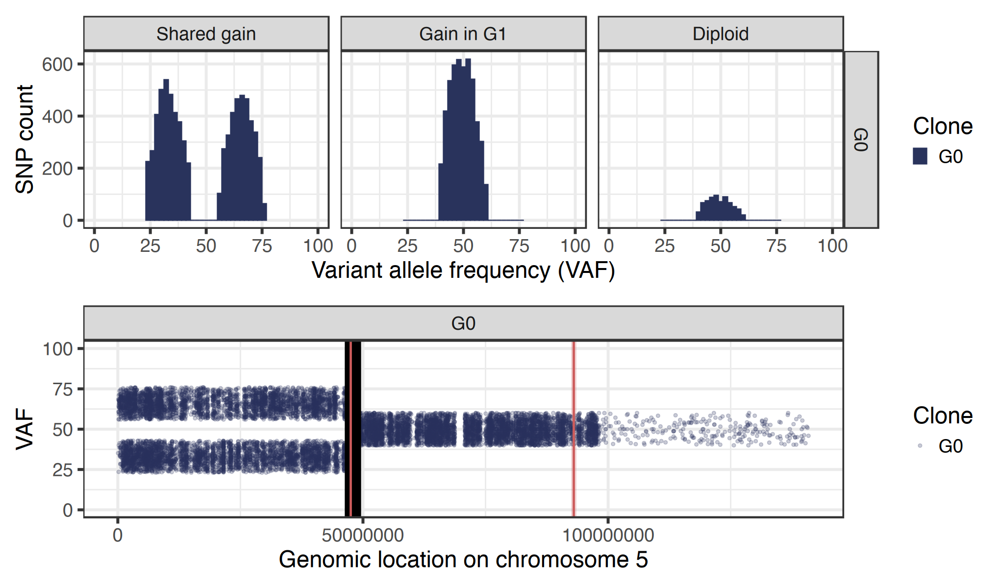

In [22]:
# 1. G0
clone_df <- distinct(counts_c0, Clone)
# VAF by genomic position

p1 <- ggplot()+
  geom_rect(  data = clone_df,
              aes(xmin=93000000-500000, xmax=93000000+500000, ymin=-Inf, ymax=Inf),
              fill = "indianred",
              alpha = 0.25)+
  geom_point(data = counts_all[counts_all$NonNACount > 0 & counts_all$Clone == "G0",], aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.25, size =1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(data = clone_df,
             xintercept = 93000000, colour = "indianred", linewidth = 1)+
  geom_rect(data = clone_df,
            aes(xmin=46405641, xmax=49495641, ymin=-Inf, ymax=Inf), color = "black", fill= "black", alpha=1)+
  geom_vline(data = clone_df,xintercept = 47500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,141000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 5")+
  #guides(fill="none", color = "none")+
  facet_wrap(vars(Clone), nrow = 2)+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region,levels = c("Shared gain","Gain in G1","Diploid"))

p2 <- ggplot(data = counts_all[counts_all$NonNACount > 0 & counts_all$Clone == "G0",], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  #guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)

options(repr.plot.width=17, repr.plot.height=10)

p2 / p1


Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”


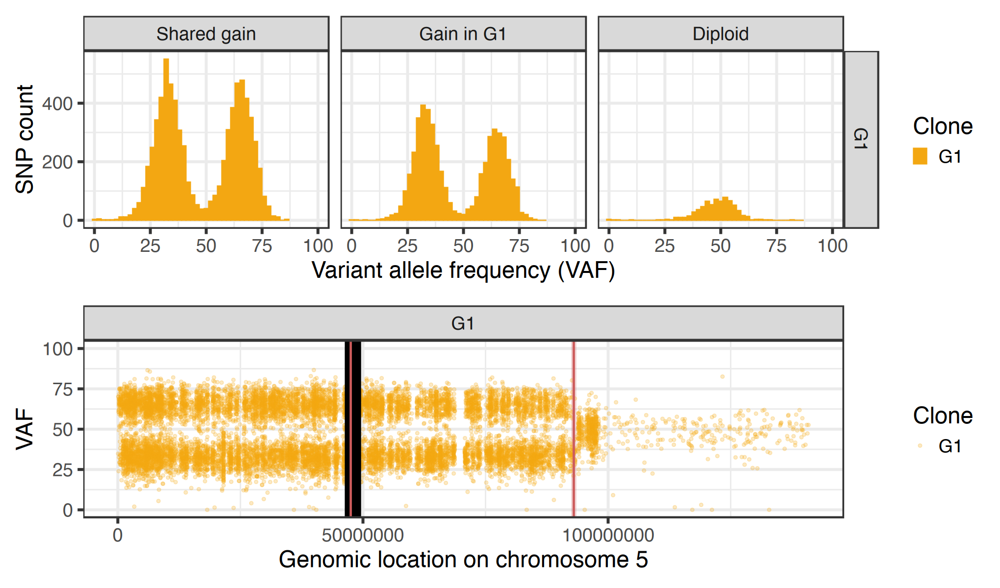

In [23]:
 # 2. G1
  
  # VAF by genomic position

clone_df <- distinct(counts_c1, Clone)

p1 <- ggplot()+
  geom_rect(  data = clone_df,
              aes(xmin=93000000-500000, xmax=93000000+500000, ymin=-Inf, ymax=Inf),
              fill = "indianred",
              alpha = 0.25)+
  geom_point(data = counts_all[counts_all$NonNACount > 0 & counts_all$Clone == "G1",],
             aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.25, size =1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(data = clone_df, xintercept = 93000000, colour = "indianred", linewidth = 1)+
  
  geom_rect(data = clone_df,
            aes(xmin=46405641, xmax=49495641, ymin=-Inf, ymax=Inf), color = "black", fill= "black", alpha=1)+
  geom_vline(data = clone_df, xintercept = 47500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,141000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 5")+
  facet_wrap(vars(Clone), nrow = 2)+
  #guides(fill="none", color = "none")+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region,levels = c("Shared gain","Gain in G1","Diploid"))

p2 <- ggplot(data = counts_all[counts_all$NonNACount > 0 & counts_all$Clone == "G1",], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  #guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)

options(repr.plot.width=17, repr.plot.height=10)
p2 / p1


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


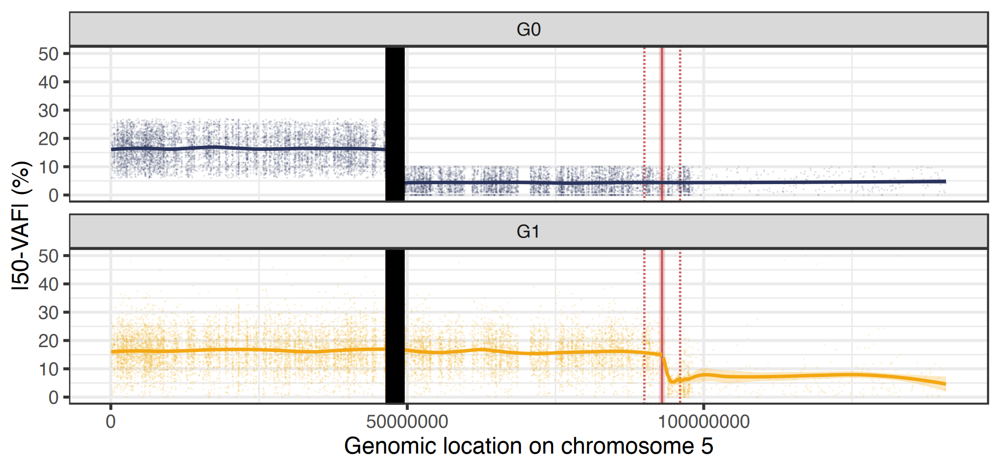

In [24]:
# Plot the absolute distance from 50% of SNP VAFs for each clone by location 
  
clone_df <- distinct(counts_all, Clone)
p <- ggplot()+
  geom_rect(  data = clone_df,
              aes(xmin=93000000-500000, xmax=93000000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(  data = clone_df,
              aes(xmin=93000000-3000000, xmax=93000000+3000000, ymin=-Inf, ymax=Inf), color = "indianred", linetype = 2, fill = NA, linewidth = 1)+
  geom_vline(xintercept = 46500000, colour = "indianred", linewidth = 1)+
  geom_vline(xintercept = 93000000, colour = "indianred", linewidth = 1)+ 
  geom_point(data = counts_all, aes(x = Location, y = abs(50-VariantFreq), color = Clone, fill = Clone),alpha = 0.1, size = 0.1)+
  geom_smooth(data = counts_all[counts_all$Location <= 46500000 ,],aes(x = Location, 
                                                                       y = abs(50-VariantFreq), 
                                                                       color = Clone,
                                                                       fill= Clone),
              method = "loess",span = 0.4, alpha = 0.25, linewidth = 1.5)+
  geom_smooth(data = counts_all[counts_all$Location > 46500000 & counts_all$Location <= 93000000 &
                                  counts_all$Clone == "G1",],aes(x = Location, 
                                                                 y = abs(50-VariantFreq), 
                                                                 color = Clone,
                                                                 fill= Clone),
              method = "loess",span = 0.4, alpha = 0.25, linewidth = 1.5)+
  geom_smooth(data = counts_all[counts_all$Location > 46500000  &
                                  counts_all$Clone == "G0",],aes(x = Location, 
                                                                 y = abs(50-VariantFreq), 
                                                                 color = Clone,
                                                                 fill= Clone),
              method = "loess",span = 0.4, alpha = 0.25, linewidth = 1.5)+
  geom_smooth(data = counts_all[counts_all$Location > 93000000 &
                                  counts_all$Clone == "G1",],aes(x = Location, 
                                                                 y = abs(50-VariantFreq), 
                                                                 color = Clone,
                                                                 fill= Clone),
              method = "loess",span = 0.4, alpha = 0.25, linewidth = 1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712")) +
  facet_wrap(vars(Clone), nrow = 2)+
  geom_rect(data = clone_df,
            aes(xmin=46405641, xmax=49495641, ymin=-Inf, ymax=Inf), color = "black", fill= "black", alpha=1)+
  
  coord_cartesian(ylim = c(0,50), xlim = c(1,141000000))+
  guides(color = "none", fill = "none")+
  ylab("|50-VAF| (%)") +
  xlab("Genomic location on chromosome 5")+
  theme_bw(base_size = 28)

options(repr.plot.width=17, repr.plot.height=8)

p
  

In [25]:
# Linear regression of the VAFs' absolute distance from 50 in each clone
  # distance from breakpoints to consider
 flank <- 1000000

counts_all_lm <- counts_all %>% mutate(AbsVAF = abs(VariantFreq-50)) %>%
  mutate(CopyNumber = case_when(Location <= 49500000 ~ 30,
                                (Location > 49500000 & Clone == "G0") ~ 20,
                                (Location > 49500000 & Location <= 93000000 & Clone == "G1") ~ 30,
                                (Location > 93000000 & Clone == "G1") ~ 20)) %>%
  mutate(G0 = case_when(Clone == "G0" ~ 1,
                        Clone == "G1" ~ 0 )) %>%
  mutate(B2L = case_when((Location <= 93000000  & Location >= 93000000  - flank ) ~ 1,
                         .default = 0))%>%
  mutate(B2R = case_when((Location <= 93000000   + flank & Location > 93000000  ) ~ 1,
                         .default = 0)) %>% 
  mutate(Open = case_when(SNP_ID %in% intersect(heterozygous_snps_open_c0,heterozygous_snps_open_c1) ~1,
                            .default = 0)) %>%
  mutate(G0Open = case_when(SNP_ID %in% heterozygous_snps_open_c0[! heterozygous_snps_open_c0 %in% heterozygous_snps_open_c1] ~1,
                            .default = 0)) %>%
  mutate(G1Open = case_when(SNP_ID %in% heterozygous_snps_open_c1[! heterozygous_snps_open_c1 %in% heterozygous_snps_open_c0]  ~ 1,
                            .default = 0)) %>%
  select(SNP_ID,AbsVAF,G0,Open,G0Open,G1Open,CopyNumber,B2L, B2R)

write_csv(counts_all_lm,"../Data/SNP_Data/WGS/Chr5/Chr5_WGS_HetSNPs_G0AndG1_Info_LinearModel.csv")

snp_lm_model_c1 <- lm(formula = (AbsVAF) ~ Open  + CopyNumber +  B2L + B2R, 
                      data = counts_all_lm[counts_all_lm$G0 == 0,])
snp_lm_model_c0 <- lm(formula = (AbsVAF) ~ Open  + CopyNumber +  B2L + B2R, 
                      data = counts_all_lm[counts_all_lm$G0 == 1,])

 print("Linear regression for clone G0:")
summary(snp_lm_model_c0, robust = T)

print("Linear regression for clone G1:")
summary(snp_lm_model_c1, robust = T)


[1] "Linear regression for clone G0:"



Call:
lm(formula = (AbsVAF) ~ Open + CopyNumber + B2L + B2R, data = counts_all_lm[counts_all_lm$G0 == 
    1, ])

Residuals:
     Min       1Q   Median       3Q      Max 
-15.4584  -2.9638  -0.1162   3.0544  10.5213 

Coefficients:
             Estimate Std. Error t value            Pr(>|t|)    
(Intercept) -19.62650    0.19694 -99.656 <0.0000000000000002 ***
Open          0.16564    0.35085   0.472               0.637    
CopyNumber    1.20094    0.00753 159.496 <0.0000000000000002 ***
B2L          -0.66887    0.56293  -1.188               0.235    
B2R          -0.43047    0.69744  -0.617               0.537    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 4.228 on 12955 degrees of freedom
Multiple R-squared:  0.6652,	Adjusted R-squared:  0.6651 
F-statistic:  6436 on 4 and 12955 DF,  p-value: < 0.00000000000000022


[1] "Linear regression for clone G1:"



Call:
lm(formula = (AbsVAF) ~ Open + CopyNumber + B2L + B2R, data = counts_all_lm[counts_all_lm$G0 == 
    0, ])

Residuals:
    Min      1Q  Median      3Q     Max 
-16.271  -4.049  -0.095   3.859  43.359 

Coefficients:
             Estimate Std. Error t value             Pr(>|t|)    
(Intercept) -12.62023    0.72982 -17.292 < 0.0000000000000002 ***
Open          0.34326    0.51573   0.666              0.50569    
CopyNumber    0.96305    0.02469  39.010 < 0.0000000000000002 ***
B2L          -0.26047    0.82540  -0.316              0.75233    
B2R           2.81345    1.04996   2.680              0.00738 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 6.217 on 12955 degrees of freedom
Multiple R-squared:  0.1075,	Adjusted R-squared:  0.1072 
F-statistic: 390.2 on 4 and 12955 DF,  p-value: < 0.00000000000000022


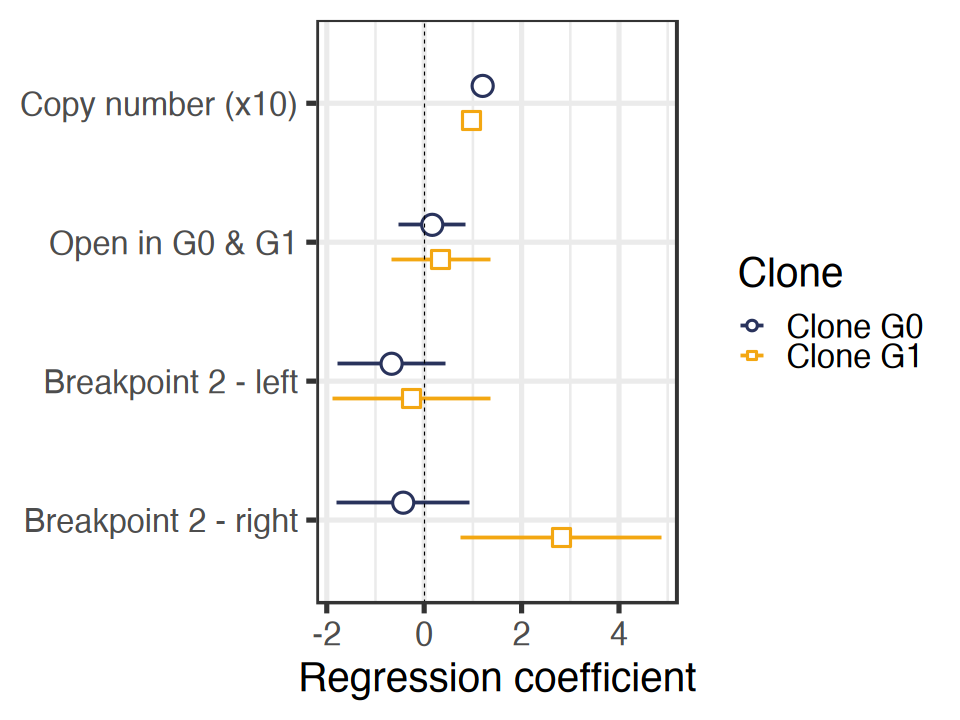

In [29]:
plot_summs(snp_lm_model_c0,snp_lm_model_c1,
                coefs = c("Copy number (x10)" = "CopyNumber", 
                          "Open in G0 & G1" = "Open",
                          "Breakpoint 2 - left" = "B2L",
                          "Breakpoint 2 - right" = "B2R"),
                colors = c("#29335c","#f3a712"),
                point.size = 10,
                model.names = c("Clone G0","Clone G1"),
                legend.title = "Clone") +
  xlab("Regression coefficient")+ 
  theme_bw(base_size = 24) +
  theme(axis.title.y =element_blank())


options(repr.plot.width=8, repr.plot.height=6)


### ATAC: Compute and compare the heterozygous SNP frequencies in the two copy number clones

In [30]:
atac_snp_5 <- data.frame(atac_snp_fil[grep("5_[0-9]+_[A-Z]_[A-Z]",atac_snp_fil$SNP_ID),])
rownames(atac_snp_5) <- atac_snp_5$SNP_ID


# Filter the SNP matrix to include cells in G0 and G1 
atac_snp_5_cc0 <- atac_snp_5[which(atac_snp_5$SNP_ID %in% counts_5_het_snps),
                             colnames(atac_snp_5) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr5:49500001-92500000" & groups$Altered == "0",]$Clade,]$Cell_id)]
atac_snp_5_cc1 <- atac_snp_5[which(atac_snp_5$SNP_ID %in% counts_5_het_snps),
                             colnames(atac_snp_5) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr5:49500001-92500000" & groups$Altered == "1",]$Clade,]$Cell_id)]

# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
atac_snp_5_cc0 <- atac_snp_5_cc0 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

atac_snp_5_cc1 <- atac_snp_5_cc1 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_a_c0 <- atac_snp_5_cc0[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G0") %>% dplyr::mutate(Mode = "ATAC") %>% 
  mutate(Region = case_when(Location <= 46500000 ~ "Shared gain",
                            (Location > 46500000 & Location <= 93000000) ~ "Gain in G1",
                            Location > 93000000 ~ "Diploid")) %>%
  filter((Region == "Shared gain" & NonNACount >= 6) |
           (Region == "Gain in G1" & NonNACount >= 4) |
           (Region == "Diploid" & NonNACount >= 4)  ) %>%
  left_join(counts_c1[, c("SNP_ID","Allele")], by = "SNP_ID")

counts_a_c1 <- atac_snp_5_cc1[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G1") %>% dplyr::mutate(Mode = "ATAC") %>% 
  mutate(Region = case_when(Location <= 46500000 ~ "Shared gain",
                            (Location > 46500000 & Location <= 93000000) ~ "Gain in G1",
                            Location > 93000000 ~ "Diploid")) %>%
  filter((Region == "Shared gain" & NonNACount >= 6) |
           (Region == "Gain in G1" & NonNACount >= 6) |
           (Region == "Diploid" & NonNACount >= 4)  )%>%
  left_join(counts_c1[, c("SNP_ID","Allele")], by = "SNP_ID")

write_csv(counts_a_c0,"../Data/SNP_Data/ATAC/Chr5/Chr5_ATAC_HetSNPs_G0_Info.csv")
write_csv(counts_a_c1,"../Data/SNP_Data/ATAC/Chr5/Chr5_ATAC_HetSNPs_G1_Info.csv")


counts_all <- rbind(counts_a_c0,counts_a_c1) %>% mutate(Region = case_when(Location <= 46500000 ~ "Shared gain",
                                                                           (Location > 46500000 & Location <= 93000000) ~ "Gain in G1",
                                                                           Location > 93000000 ~ "Diploid"))

Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”


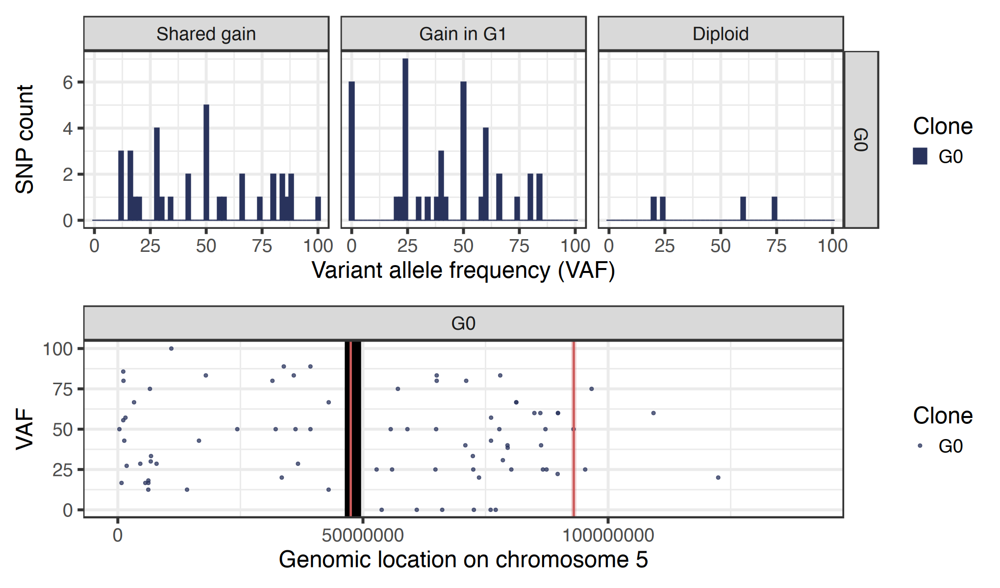

In [31]:
# Plot the SNP VAFSs for each clone by location and region
# 1. G0
  
  clone_df <- distinct(counts_a_c0, Clone)

p1 <- ggplot()+
  geom_rect(  data = clone_df,
              aes(xmin=93000000-500000, xmax=93000000+500000, ymin=-Inf, ymax=Inf),
              fill = "indianred",
              alpha = 0.25)+
  geom_point(data = counts_all[counts_all$NonNACount >=4 & counts_all$Clone == "G0",],
             aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.75, size =1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_rect(data = clone_df,
            aes(xmin=46405641, xmax=49495641, ymin=-Inf, ymax=Inf), color = "black", fill= "black", alpha=1)+
  geom_vline(data= clone_df, xintercept = 47500000, colour = "indianred", linewidth = 1)+
  geom_vline(data= clone_df, xintercept = 93000000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,141000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 5")+
  #guides(fill="none", color = "none")+
  facet_wrap(vars(Clone), nrow = 2)+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region,levels = c("Shared gain","Gain in G1","Diploid"))

p2 <- ggplot(data = counts_all[counts_all$NonNACount >= 4 & counts_all$Clone == "G0",], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  #guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1  

Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”


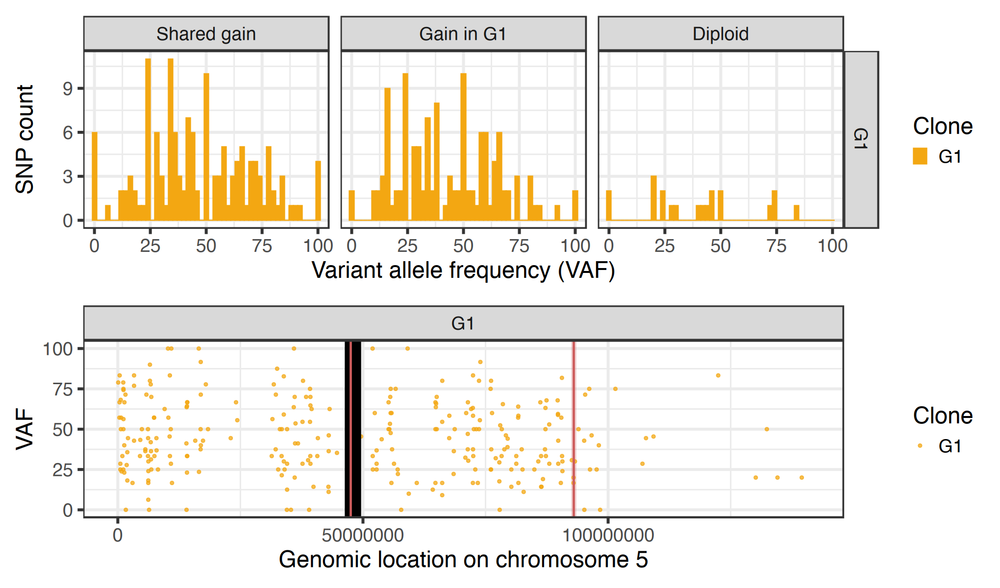

In [32]:
# 2. G1

# VAF by genomic position
clone_df <- distinct(counts_a_c1, Clone)

p1 <- ggplot()+
  geom_rect(  data = clone_df,
                   aes(xmin=93000000-500000, xmax=93000000+500000, ymin=-Inf, ymax=Inf),
                   fill = "indianred",
                   alpha = 0.25)+
  geom_point(data = counts_all[counts_all$NonNACount >=4 & counts_all$Clone == "G1",],
             aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.75, size =1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_rect(data = clone_df,
            aes(xmin=46405641, xmax=49495641, ymin=-Inf, ymax=Inf), color = "black", fill= "black", alpha=1)+
  geom_vline(data= clone_df, xintercept = 47500000, colour = "indianred", linewidth = 1)+
  geom_vline(data= clone_df, xintercept = 93000000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,141000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 5")+
  facet_wrap(vars(Clone), nrow = 2)+
  #guides(fill="none", color = "none")+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region,levels = c("Shared gain","Gain in G1","Diploid"))

p2 <- ggplot(data = counts_all[counts_all$NonNACount >= 4 & counts_all$Clone == "G1",], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  #guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1

### Comparing WGS and ATAC VAFs

`geom_smooth()` using formula = 'y ~ x'


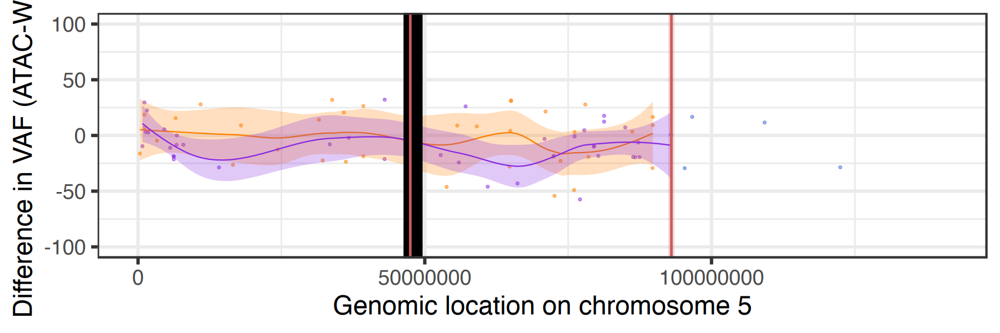

In [34]:
 # 1. G0
  sameSNPs <- intersect(counts_c0$SNP_ID,counts_a_c0$SNP_ID)

counts_c0_fil <- counts_c0[counts_c0$SNP_ID %in% sameSNPs,]
counts_c0_fil <- counts_c0_fil[order(counts_c0_fil$Location),]

counts_a_c0_fil <- counts_a_c0[counts_a_c0$SNP_ID %in% sameSNPs,]
counts_a_c0_fil <- counts_a_c0_fil[order(counts_a_c0_fil$Location),]

counts_c0_fil$Diff <- -(counts_c0_fil$VariantFreq-counts_a_c0_fil$VariantFreq)
counts_c0_fil$VariantFreq_ATAC <- counts_a_c0_fil$VariantFreq

counts_c0_fil <- counts_c0_fil %>% dplyr::rename(VariantFreq_WGS = VariantFreq) %>%
  dplyr::mutate(Region = case_when(Location <= 46500000 ~ "Shared gain",
                                   (Location > 46500000 & Location <= 93000000) ~ "Gain in G1",
                                   Location > 93000000 ~ "Diploid")) %>%
  dplyr::mutate(Breakpoint = case_when(Location > 46500000-3000000 & Location <= 49500000+3000000 ~ 1,
                                       Location > 93000000 - 3000000 & Location <= 93000000+3000000 ~ 1,
                                       .default = 0))
counts_c0_fil$Region <- factor(counts_c0_fil$Region,levels = c("Shared gain","Gain in G1","Diploid"))

clone_df <- distinct(counts_c0_fil, Clone)


p1 <- ggplot()+
  geom_rect(  data = clone_df,
              aes(xmin=93000000-500000, xmax=93000000+500000, ymin=-Inf, ymax=Inf),
              fill = "indianred",
              alpha = 0.25)+
  geom_point(data = counts_c0_fil, 
             aes(x = Location, y = Diff, color = Allele, fill = Allele),
             alpha = 0.5, size = 1)+
  geom_smooth(data = counts_c0_fil[counts_c0_fil$Region != "Diploid",],
              aes(x = Location, y = Diff, color = Allele, fill = Allele),
              method = "loess",span = 0.5, alpha = 0.25, linewidth = 0.5)+
  scale_color_manual(name = "Allele",
                     values = c("Duplicated allele"="darkorange1",
                                "Non-duplicated allele" = "blueviolet",
                                "Unknown" = "royalblue"))+
  scale_fill_manual(name = "Allele",
                    values = c("Duplicated allele"="darkorange1",
                               "Non-duplicated allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  geom_rect(data = clone_df,
            aes(xmin=46405641, xmax=49495641, ymin=-Inf, ymax=Inf), color = "black", fill= "black", alpha=1)+
  geom_vline(xintercept = 47500000, colour = "indianred", linewidth = 1)+
  geom_vline(xintercept = 93000000, colour = "indianred", linewidth = 1)+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 5")+
  guides(fill = "none", color = "none")+
  coord_cartesian(ylim = c(-100,100), xlim = c(1,141000000))+
  theme_bw(base_size = 28)

options(repr.plot.width=15, repr.plot.height=5)
p1

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


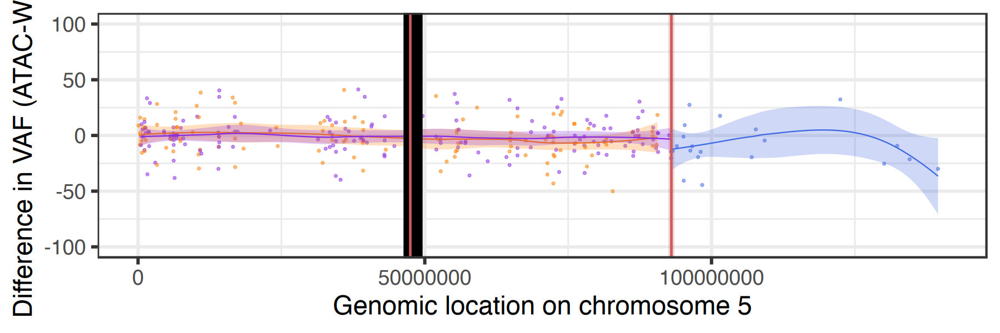

In [35]:
# 2.  G1
counts_a_c1 <- counts_a_c1 %>% dplyr::rename(SNP_ID = SNP_ID)
sameSNPs <- intersect(counts_a_c1$SNP_ID,counts_c1$SNP_ID)

counts_c1_fil <- counts_c1[counts_c1$SNP_ID %in% sameSNPs,]
counts_c1_fil <- counts_c1_fil[order(counts_c1_fil$Location),]

counts_a_c1_fil <- counts_a_c1[counts_a_c1$SNP_ID %in% sameSNPs,]
counts_a_c1_fil <- counts_a_c1_fil[order(counts_a_c1_fil$Location),]

counts_c1_fil$Diff <- (counts_a_c1_fil$VariantFreq-counts_c1_fil$VariantFreq)
counts_c1_fil$VariantFreq_ATAC <- counts_a_c1_fil$VariantFreq

counts_c1_fil <- counts_c1_fil %>% dplyr::rename(VariantFreq_WGS = VariantFreq) %>% 
  dplyr::mutate(Region = case_when(Location <= 46500000 ~ "Shared gain",
                                   (Location > 46500000 & Location <= 93000000) ~ "Gain in G1",
                                   Location > 93000000 ~ "Diploid")) %>%
  dplyr::mutate(Breakpoint = case_when(Location > 46500000-3000000 & Location <= 49500000+3000000 ~ 1,
                                       Location > 93000000 - 3000000 & Location <= 93000000+3000000 ~ 1,
                                       .default = 0))

counts_c1_fil$Region <- factor(counts_c1_fil$Region,levels = c("Shared gain","Gain in G1","Diploid"))
clone_df <- distinct(counts_c1_fil, Clone)

p2 <- ggplot()+
  geom_rect(  data = clone_df,
              aes(xmin=93000000-500000, xmax=93000000+500000, ymin=-Inf, ymax=Inf),
              fill = "indianred",
              alpha = 0.25)+
  geom_point(data = counts_c1_fil, aes(x = Location, y = Diff, color = Allele,
                                       fill= Allele),
             alpha = 0.5, size = 1)+
  geom_smooth(data = counts_c1_fil[counts_c1_fil$Region != "Diploid",],aes(x = Location, 
                                                                               y = Diff, 
                                                                               color = Allele,
                                                                               fill= Allele),
              method = "loess",span = 0.5, alpha = 0.25, linewidth = 0.5)+
  geom_smooth(data = counts_c1_fil[counts_c1_fil$Region == "Diploid",],aes(x = Location, 
                                                                           y = Diff, 
                                                                           color = Allele,
                                                                           fill= Allele),
              method = "loess",span = 1, alpha = 0.25, linewidth = 0.5)+
  scale_color_manual(name = "Allele",
                     values = c("Duplicated allele"="darkorange1",
                                "Non-duplicated allele" = "blueviolet",
                                "Unknown" = "royalblue"))+
  scale_fill_manual(name = "Allele",
                    values = c("Duplicated allele"="darkorange1",
                               "Non-duplicated allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  geom_rect(data = clone_df,
            aes(xmin=46405641, xmax=49495641, ymin=-Inf, ymax=Inf), color = "black", fill= "black", alpha=1)+
  geom_vline(xintercept = 47500000, colour = "indianred", linewidth = 1)+
  geom_vline(xintercept = 93000000, colour = "indianred", linewidth = 1)+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 5")+
  guides(fill = "none", color = "none")+
  coord_cartesian(ylim = c(-100,100), xlim = c(1,141000000))+
  theme_bw(base_size = 28)

options(repr.plot.width=15, repr.plot.height=5)
p2

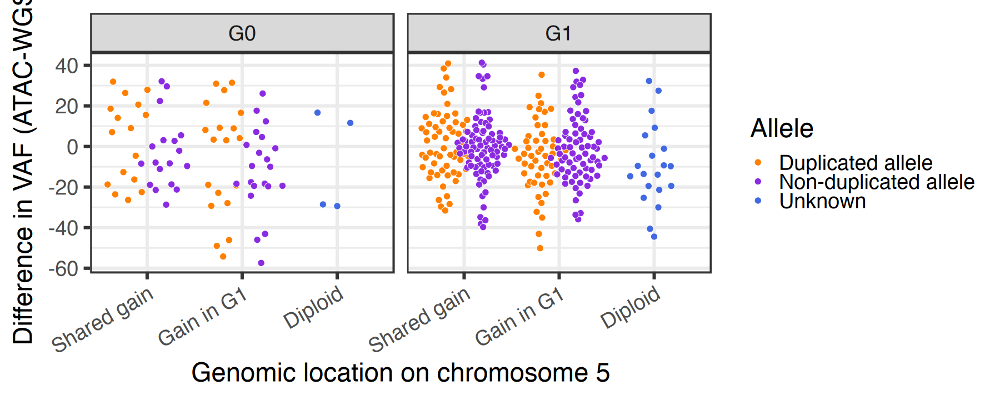

In [40]:
# 3. G0 and G1 
counts_a_fil <- rbind(counts_c0_fil,counts_c1_fil)

counts_a_fil$Region <- factor(counts_a_fil$Region,levels = c("Shared gain","Gain in G1","Diploid"))


counts_a_fila <- counts_a_fil[counts_a_fil$Clone == "G1" | (counts_a_fil$Clone == "G0" & counts_a_fil$Region != "Diploid"),]
counts_a_filb <- counts_a_fil[counts_a_fil$Clone == "G0" & counts_a_fil$Region == "Diploid",]

counts_a_fila$Region <- factor(counts_a_fila$Region,levels = c("Shared gain","Gain in G1","Diploid"))
counts_a_filb$Region <- factor(counts_a_filb$Region,levels = c("Shared gain","Gain in G1","Diploid"))
library(ggbeeswarm)
p <- ggplot(data = counts_a_fil, aes(x = Region, y = Diff, color = Allele, fill = Allele))+
  #geom_point(data = counts_a_filb, aes(x = Region, y = Diff, color = Allele, fill = Allele),
  #           alpha = 0.5)+
  #geom_violin(alpha = 0.10, width = 0.9, position = position_dodge(width=1), linewidth = 0.5)+
  #geom_boxplot(alpha = 0.25, width = 0.3, position = position_dodge(width=1), linewidth = 0.5)+
  geom_quasirandom(
    dodge.width = 0.8,
    shape = 21,
    color = "white",
    alpha = 1,
    size = 3,
    stroke = 0.3,
    width = 0.3,         # how wide the cloud is
    varwidth = TRUE      # makes the dots follow density (violin shape)
  )+
  scale_fill_manual(name = "Allele",
                    values = c("Duplicated allele"="darkorange1",
                               "Non-duplicated allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 5")+
  facet_wrap(vars(Clone),nrow = 1)+
  theme_bw(base_size = 28)+
    theme(
        axis.text.x = element_text(angle = 30, hjust = 1)
    )

options(repr.plot.width=15, repr.plot.height=6)
p

## Loss in chromosome 1

### WGS: Identify heterozygous SNPs

In [43]:
# Select for the SNPs on chromosome 1
wgs_snp_1 <- data.frame(wgs_snp[grep("1_[0-9]+_[A-Z]_[A-Z]",wgs_snp$SNP_ID),])
rownames(wgs_snp_1) <- wgs_snp_1$SNP_ID

# Identify the heterozygous SNPs using the cells which are diploid in the region
# 145-188 Mb

# Select for those cells
wgs_snp_1_dip <- wgs_snp_1[,colnames(wgs_snp_1) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr1:162000001-175000000" & groups$Altered == "0",]$Clade,]$Cell_id)] 

# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
wgs_snp_1_dip <- wgs_snp_1_dip %>% dplyr::mutate(Present = rowSums(across(everything(), ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(everything(), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(everything(), ~ .x == -1)))

counts_1_dip <- wgs_snp_1_dip[,c("SNP_ID","Present","Absent","NA")]

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_1_dip <- counts_1_dip %>% dplyr::mutate(VariantFreq =100*(Present/(Absent + Present))) %>% 
  dplyr::mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(unlist(str_split(counts_1_dip$SNP_ID,"_"))[seq(2,nrow(counts_1_dip)*4,4)])) %>%
  mutate(Region = case_when(Location <= 161000000 ~ "Shared diploid - left",
                            (Location > 161000000 & Location <= 174500000) ~ "Loss in G1",
                            Location > 174500000 ~ "Shared diploid - right"))

# Save the SNP info
write_csv(counts_1_dip, "../Data/SNP_Data/WGS/Chr1/Chr1_WGS_AllSNPs_Info.csv")

# Filter for heterozygous SNPs, which have at least 10 support reads 
# (i.e., 10 cells with the SNP)
counts_1_het <- counts_1_dip %>% filter(VariantFreq >= 40 & VariantFreq <= 60) %>% 
  filter(Present >= 10)


# heterozygous SNP ids
counts_1_het_snps <- counts_1_het$SNP_ID

# Save the heterozygous SNP info
write_csv(counts_1_het, "../Data/SNP_Data/WGS/Chr1/Chr1_WGS_HetSNPs_Info.csv")


### Compute and compare the heterozygous SNP frequencies in the two copy number clones

In [50]:
# Filter the SNP matrix to include cells in G0 and G1 - exclude the cells that don't have the alteration (they bias the SNPs)
wgs_snp_1_cc0 <- wgs_snp_1[rownames(wgs_snp_1) %in% counts_1_het_snps,
                           colnames(wgs_snp_1) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr1:162000001-175000000" & groups$Altered == "0",]$Clade 
                                                                      & ! clades$Cell_id %in% c("SW620bc_DSIb_DATAC_E12",
                                                                                                "SW620bc_DT1_P1a_DATAC_B1",
                                                                                                "SW620bc_DT1_P1a_DATAC_B20",
                                                                                                "SW620bc_DT1_P1a_DATAC_F5",
                                                                                                "SW620bc_DT1_P1a_DATAC_P14",
                                                                                                "SW620bc_DT1_P1b_DATAC_I7",
                                                                                                "SW620bc_DT1_P1a_DATAC_C23",
                                                                                                "SW620bc_POTm_day3_DATAC_F11",
                                                                                                "SW620bc_POTm_day3_DATAC_P5"),]$Cell_id)]
wgs_snp_1_cc1 <- wgs_snp_1[rownames(wgs_snp_1) %in% counts_1_het_snps,
                           colnames(wgs_snp_1) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr1:162000001-175000000" & groups$Altered == "1"
                                                                                             ,]$Clade  & ! clades$Cell_id %in% c("SW620bc_DSIVb_R_DATAC_K24",
                                                                                                                                 "SW620bc_DT1_P1a_DATAC_K3",
                                                                                                                                 "SW620bc_DT1_P1b_DATAC_F15",
                                                                                                                                 "SW620bc_DT1_P1b_DATAC_H19",
                                                                                                                                 "SW620bc_DT1_P1b_DATAC_J16"),]$Cell_id)]


# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
wgs_snp_1_cc0 <- wgs_snp_1_cc0 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

wgs_snp_1_cc1 <- wgs_snp_1_cc1 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_c0 <- wgs_snp_1_cc0[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G0") %>% dplyr::mutate(Mode = "WGS") %>% 
  mutate(Region = case_when(Location <= 161000000 ~ "Shared diploid - left",
                            (Location > 161000000 & Location <= 174500000) ~ "Loss in G1",
                            Location > 174500000 ~ "Shared diploid - right"))

counts_c1 <- wgs_snp_1_cc1[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G1") %>% dplyr::mutate(Mode = "WGS") %>% 
  mutate(Region = case_when(Location <= 161000000 ~ "Shared diploid - left",
                            (Location > 161000000 & Location <= 174500000) ~ "Loss in G1",
                            Location > 174500000 ~ "Shared diploid - right"))


# Filter for SNPs with at least 2 reads per allele (on average)
counts_c0 <- counts_c0 %>% filter(NonNACount >= 4)  
counts_c1 <- counts_c1 %>%
  filter((Region == "Loss in G1" & NonNACount >= 2) |
           (Region %in% c("Shared diploid - left",
                          "Shared diploid - right") 
            & NonNACount >= 4))

# Define whether SNPs are in open or closed chromatin 
# (based on ATAC signal in peaks computed for each clone)

# Peaks with positions defined in hg38
peaks_hg38 <- read_csv("../Data/ATAC_Data/PeakData/Chr1/Chr1Loss_PeakInformation.csv", col_types = "ccddccc")

# Peaks in each clone with positions defined in hg38
peaks_hg38_c0 <- read_csv("../Data/ATAC_Data/PeakData/Chr1/Chr1Loss_PeakScores_G0.csv", col_types = "cdd")
peaks_hg38_c1 <- read_csv("../Data/ATAC_Data/PeakData/Chr1/Chr1Loss_PeakScores_G1.csv", col_types = "cdd")

# Create text files with the peak position for liftover
loc_c0 <- noquote(sprintf("%s:%s-%s",peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c0$Peak_ID,]$chrom,
                          peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c0$Peak_ID,]$start,
                          peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c0$Peak_ID,]$end))
write.table(loc_c0,"../Data/ATAC_Data/PeakData/Chr1/Chr1Loss_PeakLocationsForLiftOver_G0.txt",
            row.names = F,col.names = F,quote =F)

loc_c1 <- noquote(sprintf("%s:%s-%s",peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c1$Peak_ID,]$chrom,
                          peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c1$Peak_ID,]$start,
                          peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c1$Peak_ID,]$end))
write.table(loc_c1,"../Data/ATAC_Data/PeakData/Chr1/Chr1Loss_PeakLocationsForLiftOver_G1.txt",
            row.names = F,col.names = F,quote =F)

# Perform liftover in UCSC Genome Browser (https://genome.ucsc.edu/cgi-bin/hgLiftOver)

# Format the peak positions in hg19 
peaks_hg19_c0 <-  data.frame(read.table("../Data/ATAC_Data/PeakData/Chr1/Chr1Loss_PeakLocations_LiftOver_G0.bed",
                                        header = FALSE, sep="\t",stringsAsFactors=FALSE, quote=""))

peaks_hg19_c0_new <- c()
for (i in 1:nrow(peaks_hg19_c0)){
  peaks_hg19_c0_new <- rbind(peaks_hg19_c0_new,str_split(peaks_hg19_c0$V1[i],":|-")[[1]])
}
peaks_hg19_c0_new <- data.frame(peaks_hg19_c0_new)
colnames(peaks_hg19_c0_new) <- c("chrom","start","end")


peaks_hg19_c1 <-  data.frame(read.table("../Data/ATAC_Data/PeakData/Chr1/Chr1Loss_PeakLocations_LiftOver_G1.bed",
                                        header = FALSE, sep="\t",stringsAsFactors=FALSE, quote=""))

peaks_hg19_c1_new <- c()
for (i in 1:nrow(peaks_hg19_c1)){
  peaks_hg19_c1_new <- rbind(peaks_hg19_c1_new,str_split(peaks_hg19_c1$V1[i],":|-")[[1]])
}
peaks_hg19_c1_new <- data.frame(peaks_hg19_c1_new)
colnames(peaks_hg19_c1_new) <- c("chrom","start","end")

counts_1_het_snps_location <- as.numeric(unlist(str_split(counts_1_het_snps,"_"))[seq(2,length(counts_1_het_snps)*4,4)])

heterozygous_snps_open_c0 <- c()
for (i in 1:length(counts_1_het_snps)){
  ind <- which(peaks_hg19_c0_new$start <= counts_1_het_snps_location[i] & peaks_hg19_c0_new$end >= counts_1_het_snps_location[i])
  if (length(ind) == 0){
    next
  } else {
    heterozygous_snps_open_c0 <- c(heterozygous_snps_open_c0, counts_1_het_snps[i])
  }
}

heterozygous_snps_open_c1 <- c()
for (i in 1:length(counts_1_het_snps)){
  ind <- which(peaks_hg19_c1_new$start <= counts_1_het_snps_location[i] & peaks_hg19_c1_new$end >= counts_1_het_snps_location[i])
  if (length(ind) == 0){
    next
  }else {
    heterozygous_snps_open_c1 <- c(heterozygous_snps_open_c1, counts_1_het_snps[i])
  }
}

counts_c1 <- counts_c1 %>% mutate("Chromatin state" = case_when(SNP_ID %in% heterozygous_snps_open_c1 ~ "Open",
                                                                .default = "Closed")) %>% 
  mutate(Allele = case_when(Region == "Loss in G1" & VariantFreq < 50 ~ "Lost allele",
                            Region == "Loss in G1" & VariantFreq >= 50 ~ "Remaining allele",
                            .default = "Unknown"))


counts_c0 <- counts_c0 %>% mutate("Chromatin state" = case_when(SNP_ID %in% heterozygous_snps_open_c0 ~ "Open",
                                                                .default = "Closed")) %>%
  left_join(counts_c1[,c("SNP_ID","Allele")], by = "SNP_ID")
counts_c0$Allele[is.na(counts_c0$Allele)] <- "Unknown"


write_csv(counts_c0,"../Data/SNP_Data/WGS/Chr1/Chr1_WGS_HetSNPs_G0_Info.csv")
write_csv(counts_c1,"../Data/SNP_Data/WGS/Chr1/Chr1_WGS_HetSNPs_G1_Info.csv")

# Combine G0 and CG SNP VAFs into one dataframe
counts_all <- rbind(counts_c0,counts_c1) 
write_csv(counts_all,"../Data/SNP_Data/WGS/Chr1/Chr1_WGS_HetSNPs_G0AndG1_Info.csv")


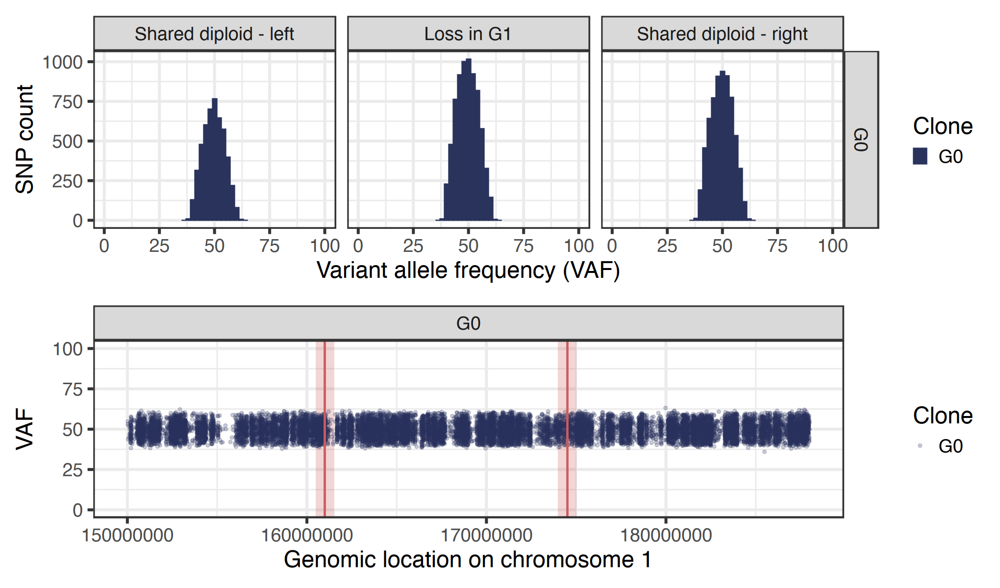

In [51]:
 # Plot the SNP VAFSs for each clone by location and region
  # 1. G0
  
  clone_df <- distinct(counts_c0, Clone)

p1 <- ggplot()+
  geom_rect(data= clone_df,
            aes(xmin=161000000-500000, xmax=161000000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(data= clone_df,
            aes(xmin=174500000-500000, xmax=174500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G0"&
                                 counts_all$Location > 150000000,],
             aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.25, size = 1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(xintercept = 161000000, colour = "indianred", linewidth = 1)+
  geom_vline(xintercept = 174500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(150000000,188000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 1")+
  #guides(fill="none", color = "none")+
  facet_wrap(vars(Clone), nrow = 2)+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region, levels = c("Shared diploid - left","Loss in G1","Shared diploid - right"))

p2 <- ggplot(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G0"&
                                 counts_all$Location > 150000000,], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  #guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1
  

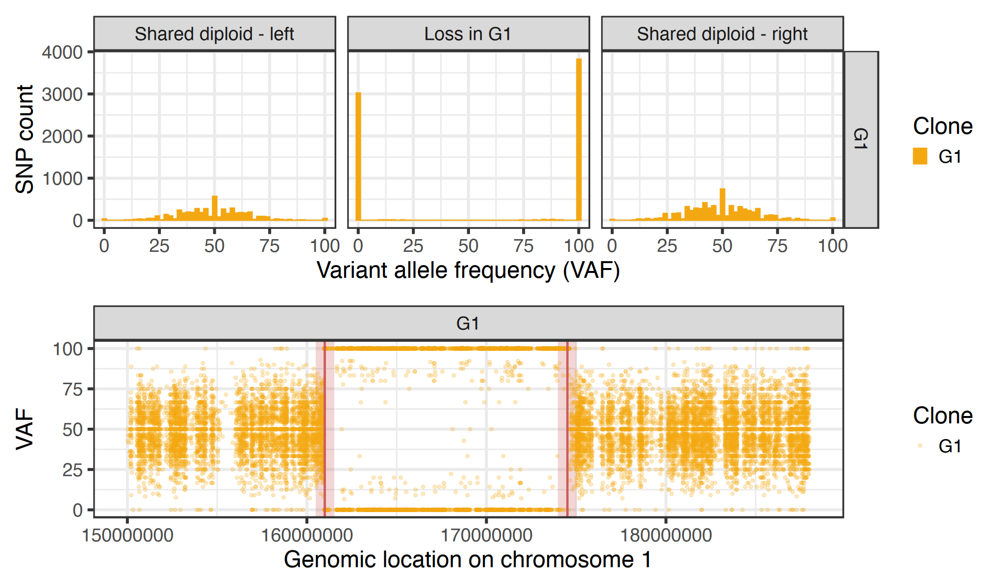

In [52]:
# 2. G1
  
  clone_df <- distinct(counts_c1, Clone)

p1 <- ggplot()+
  geom_rect(data= clone_df,
            aes(xmin=161000000-500000, xmax=161000000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(data= clone_df,
            aes(xmin=174500000-500000, xmax=174500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G1"&
                                 counts_all$Location > 150000000
                               ,], aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.25, size = 1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(xintercept = 161000000, colour = "indianred", linewidth = 1)+
  geom_vline(xintercept = 174500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(150000000,188000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 1")+
  facet_wrap(vars(Clone), nrow = 2)+
  #guides(fill="none", color = "none")+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region, levels = c("Shared diploid - left","Loss in G1","Shared diploid - right"))

p2 <- ggplot(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G1" &
                                 counts_all$Location > 150000000,], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  #guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1
  

Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


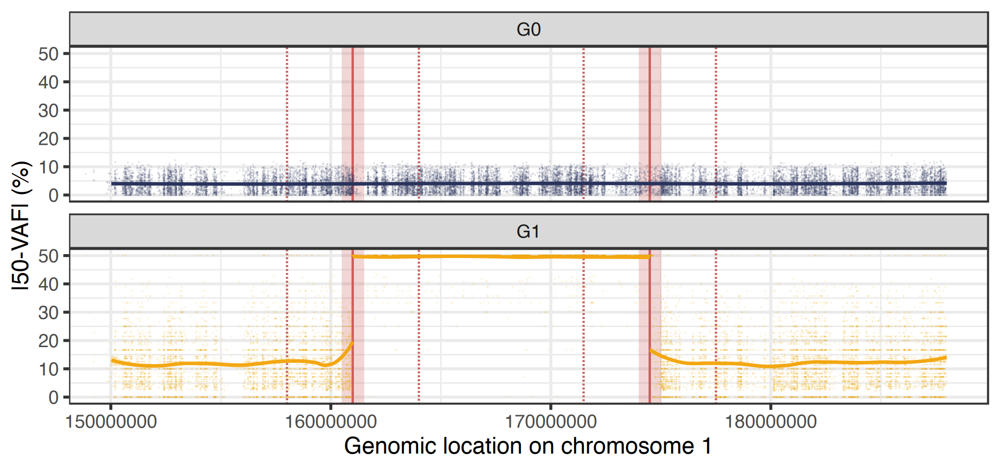

In [57]:
# Plot the absolute distance from 50% of SNP VAFs for each clone by location 
 clone_df <- distinct(counts_all, Clone)

p <- ggplot()+
  geom_rect(data= clone_df,
            aes(xmin=161000000-500000, xmax=161000000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(data= clone_df,
            aes(xmin=174500000-500000, xmax=174500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(data= clone_df,
            aes(xmin=161000000-3000000, xmax=161000000+3000000, ymin=-Inf, ymax=Inf), color = "indianred", linetype = 2, fill = NA, linewidth = 1)+
  geom_rect(data= clone_df,
            aes(xmin=174500000-3000000, xmax=174500000+3000000, ymin=-Inf, ymax=Inf), color = "indianred", linetype = 2, fill = NA, linewidth = 1)+
  geom_vline(data= clone_df,
             xintercept = 161000000, colour = "indianred", linewidth = 1)+
  geom_vline(data= clone_df,
             xintercept = 174500000, colour = "indianred", linewidth = 1)+
  geom_point(data = counts_all, aes(x = Location, y = abs(50-VariantFreq), color = Clone, fill = Clone),alpha = 0.1, size = 0.05)+
  geom_smooth(data = counts_all[counts_all$Location > 150000000 & counts_all$Location <= 161000000 &
                                  counts_all$Clone == "G1",],aes(x = Location, 
                                                                       y = abs(50-VariantFreq), 
                                                                       color = Clone,
                                                                       fill= Clone),
              method = "loess",span = 0.4, alpha = 0.25, linewidth = 1.5)+
  geom_smooth(data = counts_all[counts_all$Location > 161000000 & counts_all$Location <= 174500000 &
                                  counts_all$Clone == "G1",],aes(x = Location, 
                                                                 y = abs(50-VariantFreq), 
                                                                 color = Clone,
                                                                 fill= Clone),
              method = "loess",span = 0.4, alpha = 0.25, linewidth = 1.5)+
  geom_smooth(data = counts_all[counts_all$Location > 150000000  &
                                  counts_all$Clone == "G0",],aes(x = Location, 
                                                                 y = abs(50-VariantFreq), 
                                                                 color = Clone,
                                                                 fill= Clone),
              method = "loess",span = 0.4, alpha = 0.25, linewidth = 1.5)+
  geom_smooth(data = counts_all[counts_all$Location > 174500000 &
                                  counts_all$Clone == "G1",],aes(x = Location, 
                                                                 y = abs(50-VariantFreq), 
                                                                 color = Clone,
                                                                 fill= Clone),
              method = "loess",span = 0.4, alpha = 0.25, linewidth = 1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712")) +
  facet_wrap(vars(Clone), nrow = 2)+
  coord_cartesian(ylim = c(0,50), xlim = c(150000000,188000000))+
  guides(color = "none", fill = "none")+
  ylab("|50-VAF| (%)") +
  xlab("Genomic location on chromosome 1")+
  theme_bw(base_size = 28)

options(repr.plot.width=17, repr.plot.height=8)
p

In [53]:
# Linear regression of the VAFs' absolute distance from 50 in each clone
  # distance from breakpoints to consider
 flank <- 1000000
counts_all_lm <- counts_all %>% mutate(CopyNumber = case_when(Clone == "G0" ~ 20,
                                                              (Location > 161000000 & Location <= 174500000 & Clone == "G1") ~ 10,
                                                              ((Location <= 161000000 | Location > 174500000)  & Clone == "G1") ~ 20 )) %>%
  mutate(AbsVAF = abs(50-VariantFreq)) %>%
  mutate(G0 = case_when(Clone == "G0" ~ 1,
                        Clone == "G1" ~ 0 ))%>%
  mutate(B1 = case_when((Location <= 161000000 + flank & Location >= 161000000 - flank ) ~ 1,
                        .default = 0)) %>%
  mutate(B1L = case_when((Location <= 161000000 & Location >= 161000000 - flank ) ~ 1,
                         .default = 0))%>%
  mutate(B1R = case_when((Location <= 161000000 + flank & Location > 161000000 ) ~ 1,
                         .default = 0))%>%
  mutate(B2 = case_when((Location <= 174500000+flank & Location >= 174500000 - flank ) ~ 1,
                        .default = 0)) %>%
  mutate(B2L = case_when((Location <= 174500000 & Location >= 174500000 - flank ) ~ 1,
                         .default = 0))%>%
  mutate(B2R = case_when((Location <= 174500000 + flank & Location > 174500000 ) ~ 1,
                         .default = 0)) %>% 
  mutate(Open = case_when(SNP_ID %in% intersect(heterozygous_snps_open_c0,heterozygous_snps_open_c1) ~1,
                          .default = 0)) %>%
  mutate(G0Open = case_when(SNP_ID %in% heterozygous_snps_open_c0[! heterozygous_snps_open_c0 %in% heterozygous_snps_open_c1] ~1,
                            .default = 0)) %>%
  mutate(G1Open = case_when(SNP_ID %in% heterozygous_snps_open_c1[! heterozygous_snps_open_c1 %in% heterozygous_snps_open_c0]  ~ 1,
                            .default = 0)) %>%
  select(SNP_ID, AbsVAF,G0,Open,G1Open, G0Open, CopyNumber,B1L, B1R, B2L, B2R)

snp_lm_model_c1 <- lm(formula = AbsVAF ~ Open + CopyNumber+ B1L + B1R + B2L +B2R , 
                      data = counts_all_lm[counts_all_lm$G0 == 0,])
snp_lm_model_c0 <- lm(formula = AbsVAF ~  Open +  B1L + B1R + B2L +B2R , 
                      data = counts_all_lm[counts_all_lm$G0 == 1,])

print("Linear regression for clone G0:")
summary(snp_lm_model_c0, robust = T)

print("Linear regression for clone G1:")
summary(snp_lm_model_c1, robust = T)


write_csv(counts_all_lm,"../Data/SNP_Data/WGS/Chr1/Chr1_WGS_HetSNPs_G0AndG1_Info_LinearModel.csv")


[1] "Linear regression for clone G0:"



Call:
lm(formula = AbsVAF ~ Open + B1L + B1R + B2L + B2R, data = counts_all_lm[counts_all_lm$G0 == 
    1, ])

Residuals:
    Min      1Q  Median      3Q     Max 
-4.0279 -2.2735 -0.4047  1.9721  9.9721 

Coefficients:
            Estimate Std. Error t value            Pr(>|t|)    
(Intercept)  4.02789    0.02104 191.456 <0.0000000000000002 ***
Open        -0.56197    0.23971  -2.344              0.0191 *  
B1L         -0.16125    0.10216  -1.579              0.1145    
B1R         -0.13902    0.18397  -0.756              0.4499    
B2L         -0.15302    0.15836  -0.966              0.3339    
B2R         -0.12348    0.10782  -1.145              0.2521    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.723 on 18780 degrees of freedom
Multiple R-squared:  0.0005552,	Adjusted R-squared:  0.0002891 
F-statistic: 2.086 on 5 and 18780 DF,  p-value: 0.06394


[1] "Linear regression for clone G1:"



Call:
lm(formula = AbsVAF ~ Open + CopyNumber + B1L + B1R + B2L + B2R, 
    data = counts_all_lm[counts_all_lm$G0 == 0, ])

Residuals:
    Min      1Q  Median      3Q     Max 
-49.573  -4.923   0.427   0.748  38.090 

Coefficients:
            Estimate Std. Error  t value             Pr(>|t|)    
(Intercept) 87.08006    0.21556  403.965 < 0.0000000000000002 ***
Open        -0.15623    0.71422   -0.219                0.827    
CopyNumber  -3.75069    0.01285 -291.957 < 0.0000000000000002 ***
B1L          2.56970    0.30852    8.329 < 0.0000000000000002 ***
B1R         -0.18306    0.55134   -0.332                0.740    
B2L         -0.32132    0.48320   -0.665                0.506    
B2R          1.82969    0.32622    5.609         0.0000000207 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 8.078 on 18475 degrees of freedom
Multiple R-squared:  0.8337,	Adjusted R-squared:  0.8337 
F-statistic: 1.544e+04 on 6 and 18475 DF,  p-value: < 

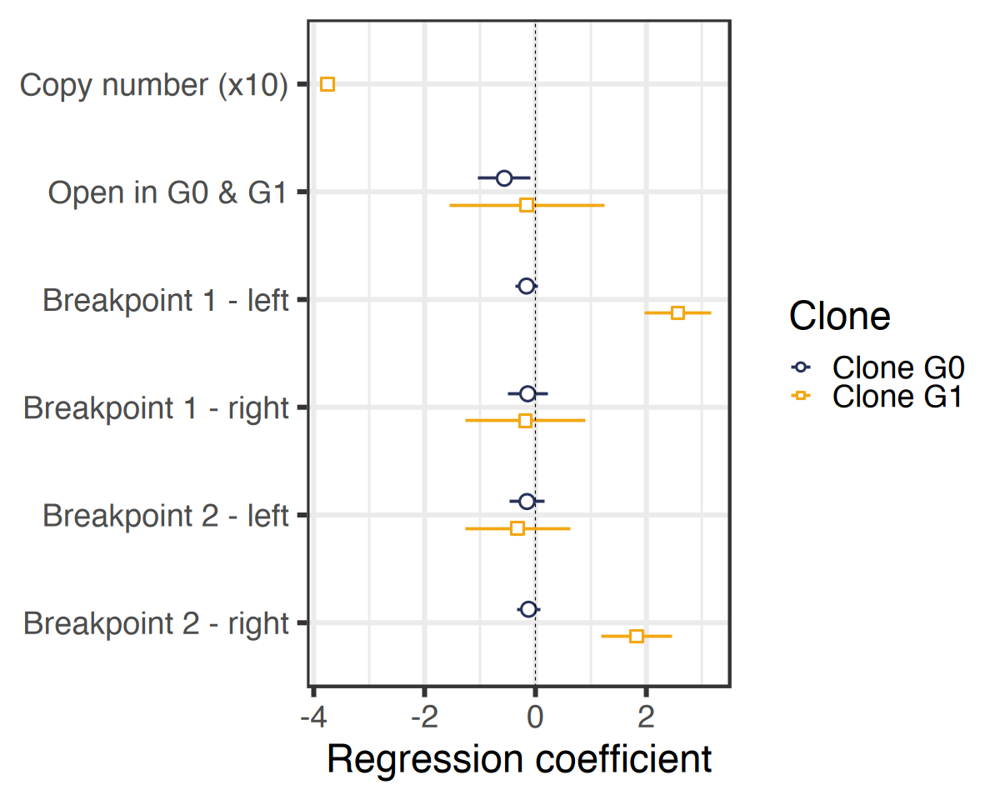

In [54]:
p <-  plot_summs(snp_lm_model_c0,snp_lm_model_c1,
           coefs = c("Copy number (x10)" = "CopyNumber", 
                     "Open in G0 & G1" = "Open",
                     "Breakpoint 1 - left" = "B1L",
                     "Breakpoint 1 - right" = "B1R",
                     "Breakpoint 2 - left" = "B2L",
                     "Breakpoint 2 - right" = "B2R"),
           colors = c("#29335c","#f3a712"),
           point.size = 8,
           model.names = c("Clone G0","Clone G1"),
           legend.title = "Clone") +
  xlab("Regression coefficient")+ 
  theme_bw(base_size = 28) +
  theme(axis.title.y =element_blank())

options(repr.plot.width=10, repr.plot.height=8)
p

### ATAC: Compute and compare the heterozygous SNP frequencies in the two copy number clones

In [58]:
atac_snp_1 <- data.frame(atac_snp_fil[grep("1_[0-9]+_[A-Z]_[A-Z]",atac_snp_fil$SNP_ID),])
rownames(atac_snp_1) <- atac_snp_1$SNP_ID


# Filter the SNP matrix to include cells in G0 and G1 
atac_snp_1_cc0 <- atac_snp_1[which(atac_snp_1$SNP_ID %in% counts_1_het_snps),
                             colnames(atac_snp_1) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr1:162000001-175000000" & groups$Altered == "0",]$Clade,]$Cell_id)]
atac_snp_1_cc1 <- atac_snp_1[which(atac_snp_1$SNP_ID %in% counts_1_het_snps),
                             colnames(atac_snp_1) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr1:162000001-175000000" & groups$Altered == "1",]$Clade,]$Cell_id)]

# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
atac_snp_1_cc0 <- atac_snp_1_cc0 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

atac_snp_1_cc1 <- atac_snp_1_cc1 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_a_c0 <- atac_snp_1_cc0[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G0") %>% dplyr::mutate(Mode = "ATAC") %>% 
  mutate(Region = case_when(Location <= 161000000 ~ "Shared diploid - left",
            (Location > 161000000 & Location <= 174500000) ~ "Loss in G1",
            Location > 174500000 ~ "Shared diploid - right")) %>%
  filter((Region == "Shared diploid - left" & NonNACount >= 4) |
           (Region == "Loss in G1" & NonNACount >= 4) |
           (Region == "Shared diploid - right" & NonNACount >= 4)  )%>%
  left_join(counts_c0[,c("SNP_ID","Allele")], by = "SNP_ID")

counts_a_c1 <- atac_snp_1_cc1[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G1") %>% dplyr::mutate(Mode = "ATAC") %>% 
  mutate(Region = case_when(Location <= 161000000 ~ "Shared diploid - left",
            (Location > 161000000 & Location <= 174500000) ~ "Loss in G1",
            Location > 174500000 ~ "Shared diploid - right") )%>%
  filter((Region == "Shared diploid - left" & NonNACount >= 4) |
           (Region == "Loss in G1" & NonNACount >= 2) |
           (Region == "Shared diploid - right" & NonNACount >= 4)  )%>%
  left_join(counts_c0[,c("SNP_ID","Allele")], by = "SNP_ID")

write_csv(counts_a_c0,"../Data/SNP_Data/WGS/Chr1/Chr1_ATAC_HetSNPs_G0_Info.csv")
write_csv(counts_a_c1,"../Data/SNP_Data/WGS/Chr1/Chr1_ATAC_HetSNPs_G1_Info.csv")


counts_all <- rbind(counts_a_c0,counts_a_c1) 

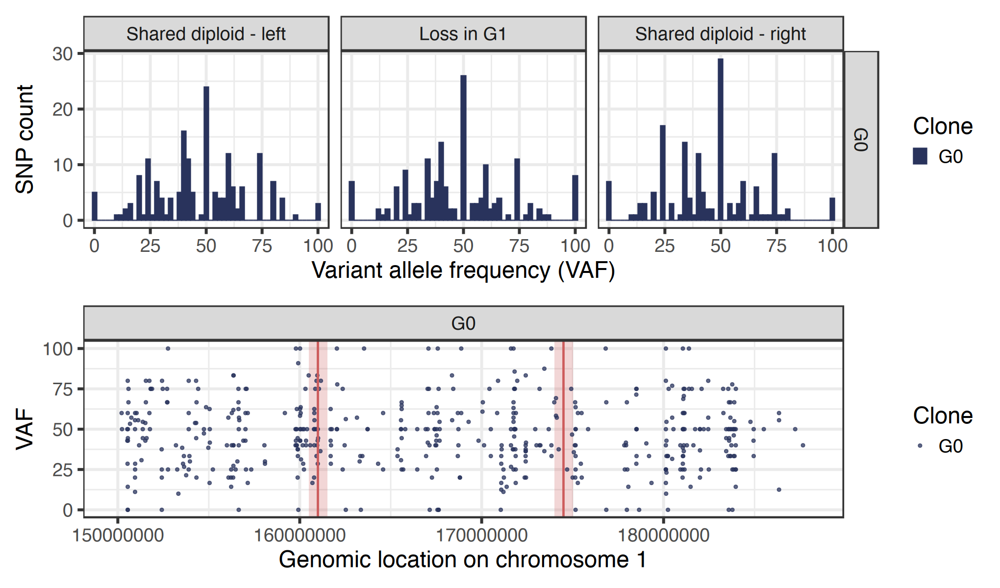

In [59]:
# Plot the SNP VAFSs for each clone by location and region
# 1. G0

clone_df <- distinct(counts_a_c0, Clone)

p1 <- ggplot()+
  geom_rect(data= clone_df,
            aes(xmin=161000000-500000, xmax=161000000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(data= clone_df,
            aes(xmin=174500000-500000, xmax=174500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[counts_all$Clone == "G0" & counts_all$Location >= 150000000,], aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.75, size =1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(xintercept = 161000000, colour = "indianred", linewidth = 1)+
  geom_vline(xintercept = 174500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(150000000,188000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 1")+
  #guides(fill="none", color = "none")+
  facet_wrap(vars(Clone), nrow = 2)+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region,levels = c("Shared diploid - left","Loss in G1","Shared diploid - right"))

p2 <- ggplot(data = counts_all[ counts_all$Clone == "G0" & counts_all$Location >= 150000000,], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  #guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1


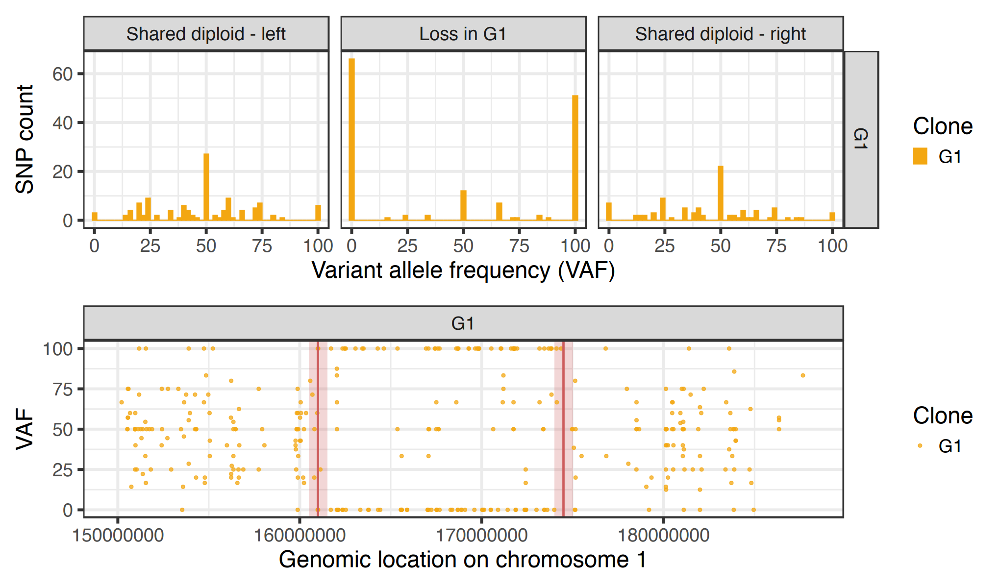

In [60]:
# 2. G1

clone_df <- distinct(counts_a_c1, Clone)

p1 <- ggplot()+
  geom_rect(data= clone_df,
            aes(xmin=161000000-500000, xmax=161000000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(data= clone_df,
            aes(xmin=174500000-500000, xmax=174500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[ counts_all$Clone == "G1" & counts_all$Location >= 150000000,],
             aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.75, size =1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(xintercept = 161000000, colour = "indianred", linewidth = 1)+
  geom_vline(xintercept = 174500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(150000000,188000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 1")+
  facet_wrap(vars(Clone), nrow = 2)+
  #guides(fill="none", color = "none")+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region,levels = c("Shared diploid - left","Loss in G1","Shared diploid - right"))

p2 <- ggplot(data = counts_all[counts_all$Clone == "G1"& counts_all$Location >= 150000000,], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  #guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1

### Comparing WGS and ATAC VAFs

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


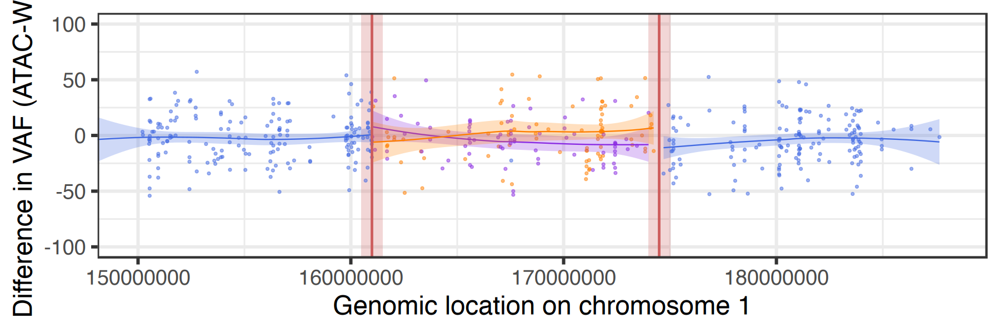

In [65]:
# 1. G0
#counts_a_c0 <- counts_a_c0 %>% dplyr::rename(SNP_ID = SNP_ID)
sameSNPs <- intersect(counts_c0$SNP_ID,counts_a_c0$SNP_ID)

counts_c0_fil <- counts_c0[counts_c0$SNP_ID %in% sameSNPs,]
counts_c0_fil <- counts_c0_fil[order(counts_c0_fil$Location),]

counts_a_c0_fil <- counts_a_c0[counts_a_c0$SNP_ID %in% sameSNPs,]
counts_a_c0_fil <- counts_a_c0_fil[order(counts_a_c0_fil$Location),]

counts_c0_fil$Diff <- -(counts_c0_fil$VariantFreq-counts_a_c0_fil$VariantFreq)
counts_c0_fil$VariantFreq_ATAC <- counts_a_c0_fil$VariantFreq

counts_c0_fil <- counts_c0_fil %>% dplyr::rename(VariantFreq_WGS = VariantFreq) %>%
  mutate(Region = case_when(Location <= 161000000 ~ "Shared diploid - left",
                            (Location > 161000000 & Location <= 174500000) ~ "Loss in G1",
                            Location > 174500000 ~ "Shared diploid - right") )%>%
  dplyr::mutate(Breakpoint = case_when(Location > 161000000-3000000 & Location <= 161000000+3000000 ~ 1,
                                       Location > 174500000  - 3000000 & Location <= 174500000 +3000000 ~ 1,
                                       .default = 0))
counts_c0_fil$Region <- factor(counts_c0_fil$Region,levels = c("Shared diploid - left","Loss in G1","Shared diploid - right"))
clone_df <- distinct(counts_c0_fil, Clone)

p1 <- ggplot()+
  geom_rect(data= clone_df,
            aes(xmin=161000000-500000, xmax=161000000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(data= clone_df,
            aes(xmin=174500000-500000, xmax=174500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_c0_fil[counts_c0_fil$Location >= 150000000,], aes(x = Location, y = Diff, color = Allele, fill = Allele),
             alpha = 0.5, size = 1)+
  geom_smooth(data = counts_c0_fil[counts_c0_fil$Region == "Loss in G1" & counts_c0_fil$Allele != "Unknown",],
              aes(x = Location, y = Diff, color = Allele, fill = Allele),
              method = "loess",span = 1, alpha = 0.25, linewidth = 0.5)+
  geom_smooth(data = counts_c0_fil[counts_c0_fil$Region == "Shared diploid - right",],
              aes(x = Location, y = Diff, color = Allele, fill = Allele),
              method = "loess",span = 1, alpha = 0.25, linewidth = 0.5)+
  geom_smooth(data = counts_c0_fil[counts_c0_fil$Region == "Shared diploid - left",],
              aes(x = Location, y = Diff, color = Allele, fill = Allele),
              method = "loess",span = 1, alpha = 0.25, linewidth = 0.5)+
  scale_color_manual(name = "Allele",
                     values =  c("Remaining allele"="darkorange1",
                                 "Lost allele" = "blueviolet",
                                 "Unknown" = "royalblue"))+
  scale_fill_manual(name = "Allele",
                    values =  c("Remaining allele"="darkorange1",
                                "Lost allele" = "blueviolet",
                                "Unknown" = "royalblue"))+
  geom_vline(xintercept = 161000000, colour = "indianred", linewidth = 1)+
  geom_vline(xintercept = 174500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(-100,100), xlim = c(150000000,188000000))+
  guides(color = "none", fill = "none")+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 1")+
  theme_bw(base_size = 28)

options(repr.plot.width=15, repr.plot.height=5)
p1

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


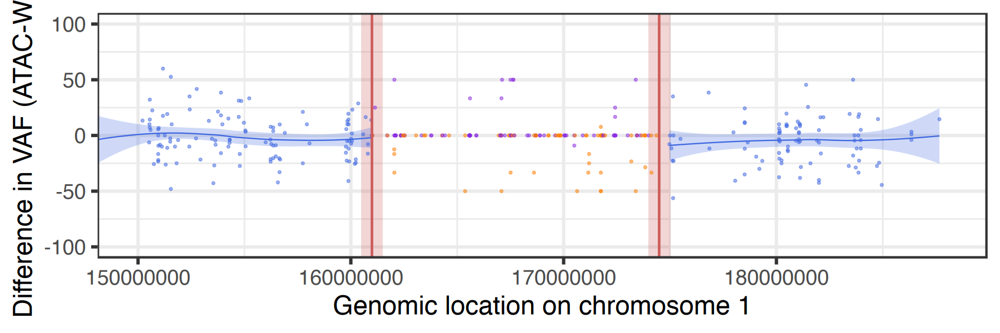

In [68]:
# 2. G1
counts_a_c1 <- counts_a_c1 %>% dplyr::rename(SNP_ID = SNP_ID)
sameSNPs <- intersect(counts_a_c1$SNP_ID,counts_c1$SNP_ID)

counts_c1_fil <- counts_c1[counts_c1$SNP_ID %in% sameSNPs,]
counts_c1_fil <- counts_c1_fil[order(counts_c1_fil$Location),]

counts_a_c1_fil <- counts_a_c1[counts_a_c1$SNP_ID %in% sameSNPs,]
counts_a_c1_fil <- counts_a_c1_fil[order(counts_a_c1_fil$Location),]

counts_c1_fil$Diff <- (counts_a_c1_fil$VariantFreq-counts_c1_fil$VariantFreq)
counts_c1_fil$VariantFreq_ATAC <- counts_a_c1_fil$VariantFreq

counts_c1_fil <- counts_c1_fil %>% dplyr::rename(VariantFreq_WGS = VariantFreq) %>% 
  mutate(Region = case_when(Location <= 161000000 ~ "Shared diploid - left",
                            (Location > 161000000 & Location <= 174500000) ~ "Loss in G1",
                            Location > 174500000 ~ "Shared diploid - right") )%>%
  dplyr::mutate(Breakpoint = case_when(Location > 161000000-3000000 & Location <= 161000000+3000000 ~ 1,
                                       Location > 174500000  - 3000000 & Location <= 174500000 +3000000 ~ 1,
                                       .default = 0))

counts_c1_fil$Region <- factor(counts_c1_fil$Region,levels =c("Shared diploid - left","Loss in G1","Shared diploid - right"))
clone_df <- distinct(counts_c1_fil, Clone)

p2 <- ggplot()+
  geom_rect(data= clone_df,
            aes(xmin=161000000-500000, xmax=161000000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(data= clone_df,
            aes(xmin=174500000-500000, xmax=174500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_c1_fil[counts_c1_fil$Location >= 150000000,], aes(x = Location, y = Diff, color = Allele,
                                                                             fill= Allele),alpha = 0.5, size = 1)+
  geom_smooth(data = counts_c1_fil[counts_c1_fil$Region == "Shared diploid - left",],aes(x = Location, 
                                                                               y = Diff, 
                                                                               color = Allele,
                                                                               fill= Allele),
              method = "loess",span = 1, alpha = 0.25, linewidth = 0.5)+
  geom_smooth(data = counts_c1_fil[counts_c1_fil$Region == "Shared diploid - right",],aes(x = Location, 
                                                                           y = Diff, 
                                                                           color = Allele,
                                                                           fill= Allele),
              method = "loess",span = 1, alpha = 0.25, linewidth = 0.5)+
  scale_color_manual(name = "Allele",
                     values = c("Remaining allele"="darkorange1",
                                "Lost allele" = "blueviolet",
                                "Unknown" = "royalblue"))+
  scale_fill_manual(name = "Allele",
                    values = c("Remaining allele"="darkorange1",
                               "Lost allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  geom_vline(xintercept = 161000000, colour = "indianred", linewidth = 1)+
  geom_vline(xintercept = 174500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(-100,100), xlim = c(150000000,188000000))+
  guides(color = "none", fill = "none")+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 1")+
  theme_bw(base_size = 28)

options(repr.plot.width=15, repr.plot.height=5)
p2

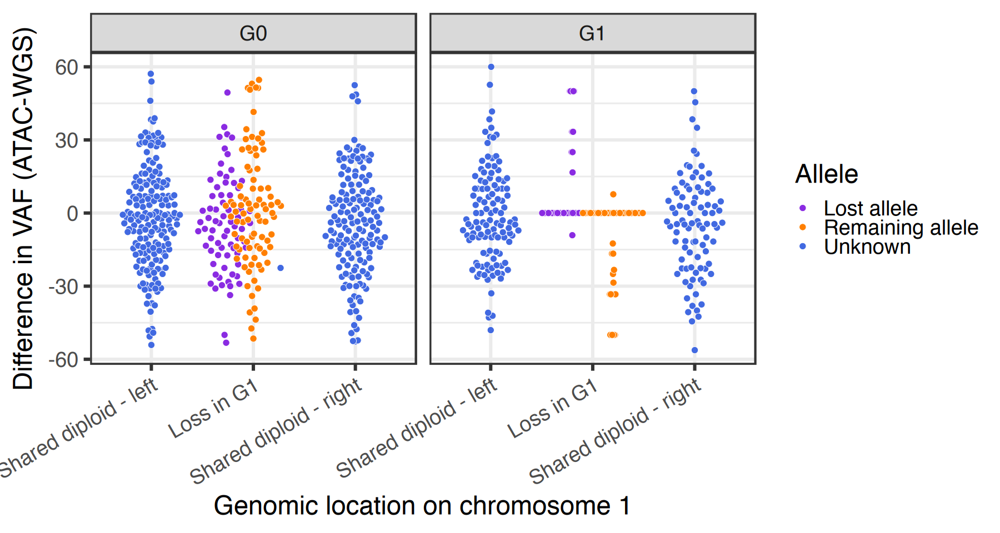

In [71]:
# 3. G0 and G1 
counts_a_fil <- rbind(counts_c0_fil,counts_c1_fil)

counts_a_fil$Region <- factor(counts_a_fil$Region,levels = c("Shared diploid - left","Loss in G1","Shared diploid - right"))


counts_a_fila <- counts_a_fil[counts_a_fil$Clone == "G1" | (counts_a_fil$Clone == "G0" & counts_a_fil$Region != "Diploid"),]
counts_a_filb <- counts_a_fil[counts_a_fil$Clone == "G0" & counts_a_fil$Region == "Diploid",]

counts_a_fila$Region <- factor(counts_a_fila$Region,levels = c("Shared gain","Gain in G1","Diploid"))
counts_a_filb$Region <- factor(counts_a_filb$Region,levels = c("Shared gain","Gain in G1","Diploid"))

p <- ggplot(data = counts_a_fil, aes(x = Region, y = Diff, color = Allele, fill = Allele))+
  #geom_point(data = counts_a_filb, aes(x = Region, y = Diff, color = Allele, fill = Allele),
  #           alpha = 0.5)+
  #geom_violin(alpha = 0.10, width = 0.9, position = position_dodge(width=1), linewidth = 0.5)+
  #geom_boxplot(alpha = 0.25, width = 0.3, position = position_dodge(width=1), linewidth = 0.5)+
  geom_quasirandom(
    dodge.width = 0.8,
    shape = 21,
    color = "white",
    alpha = 1,
    size = 3,
    stroke = 0.3,
    width = 0.3,         # how wide the cloud is
    varwidth = TRUE      # makes the dots follow density (violin shape)
  )+
  scale_fill_manual(name = "Allele",
                    values = c("Remaining allele"="darkorange1",
                               "Lost allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 1")+
  facet_wrap(vars(Clone),nrow = 1)+
  theme_bw(base_size = 28)+
    theme(
        axis.text.x = element_text(angle = 30, hjust = 1)
    )


options(repr.plot.width=15, repr.plot.height=8)
p

## Gain in chromosome 18

### WGS: Identify heterozygous SNPs

In [88]:
# Select for the SNPs on chromsome 18
wgs_snp_18 <- data.frame(wgs_snp[grep("18_[0-9]+_[A-Z]_[A-Z]",wgs_snp$SNP_ID),])
rownames(wgs_snp_18) <- wgs_snp_18$SNP_ID

# Identify the heterozygous SNPs using the cells which are diploid in the region
# 1-40 Mb

# Select for those cells
wgs_snp_18_dip <- wgs_snp_18[,colnames(wgs_snp_18) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr18:1000001-13500000" & groups$Altered == "0",]$Clade,]$Cell_id)] 

# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
wgs_snp_18_dip <- wgs_snp_18_dip %>% dplyr::mutate(Present = rowSums(across(everything(), ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(everything(), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(everything(), ~ .x == -1)))

counts_18_dip <- wgs_snp_18_dip[,c("SNP_ID","Present","Absent","NA")]

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_18_dip <- counts_18_dip %>% dplyr::mutate(VariantFreq =100*(Present/(Absent + Present))) %>% 
  dplyr::mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(unlist(str_split(counts_18_dip$SNP_ID,"_"))[seq(2,nrow(counts_18_dip)*4,4)])) %>%
  mutate(Region = case_when(Location <= 19000000 ~ "Gain in G1",
                            Location > 19000000 & Location <= 22500000 ~ "Shared diploid",
                            Location > 22500000 ~ "Shared loss"))

# Save the SNP info
write_csv(counts_18_dip, "../Data/SNP_Data/WGS/Chr18/Chr18_WGS_AllSNPs_Info.csv")

# Filter for heterozygous SNPs, which have at least 10 support reads 
# (i.e., 10 cells with the SNP)
counts_18_het <- counts_18_dip %>% filter( (Region %in% c("Gain in G1","Shared diploid") & VariantFreq >= 40 & VariantFreq <= 60)) %>% 
  filter(Present >= 10)


# heterozygous SNP ids
counts_18_het_snps <- counts_18_het$SNP_ID

# Save the heterozygous SNP info
write_csv(counts_18_het, "../Data/SNP_Data/WGS/Chr18/Chr18_WGS_HetSNPs_Info.csv")


### Compute and compare the heterozygous SNP frequencies in the two copy number clones

In [89]:
# Filter the SNP matrix to include cells in G0 and CG 
wgs_snp_18_cc0 <- wgs_snp_18[rownames(wgs_snp_18) %in% counts_18_het_snps,
                           colnames(wgs_snp_18) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr18:1000001-13500000" & groups$Altered == "0",]$Clade,]$Cell_id)]
wgs_snp_18_cc1 <- wgs_snp_18[rownames(wgs_snp_18) %in% counts_18_het_snps,
                           colnames(wgs_snp_18) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr18:1000001-13500000" & groups$Altered == "1",]$Clade,]$Cell_id)]


# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
wgs_snp_18_cc0 <- wgs_snp_18_cc0 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

wgs_snp_18_cc1 <- wgs_snp_18_cc1 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_c0 <- wgs_snp_18_cc0[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G0") %>% dplyr::mutate(Mode = "WGS") %>% 
  mutate(Region = case_when(Location <= 19000000 ~ "Gain in G1",
                            Location > 19000000 & Location <= 22500000 ~ "Shared diploid",
                            Location > 22500000 ~ "Shared loss"))


counts_c1 <- wgs_snp_18_cc1[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G1") %>% dplyr::mutate(Mode = "WGS") %>% 
  mutate(Region = case_when(Location <= 19000000 ~ "Gain in G1",
                            Location > 19000000 & Location <= 22500000 ~ "Shared diploid",
                            Location > 22500000 ~ "Shared loss"))



# Filter for SNPs with at least 2 reads per allele (on average)
counts_c0 <- counts_c0 %>% filter((Region %in% c("Gain in G1","Shared diploid") & NonNACount >= 4) |
                                    (Region %in% c("Shared loss") 
                                     & NonNACount >= 2))
counts_c1 <- counts_c1 %>%
  filter((Region == "Gain in G1" & NonNACount >= 8) |
           (Region == "Shared diploid" & NonNACount >= 4)|
           (Region %in% c("Shared loss") 
            & NonNACount >= 2))

# Define whether SNPs are in open or closed chromatin 
# (based on ATAC signal in peaks computed for each clone)

# Peaks with positions defined in hg38
peaks_hg38 <- read_csv("../Data/ATAC_Data/PeakData/Chr18/Chr18Gain_PeakInformation.csv", col_types = "ccddccc")

# Peaks in each clone with positions defined in hg38
peaks_hg38_c0 <- read_csv("../Data/ATAC_Data/PeakData/Chr18/Chr18Gain_PeakScores_G0.csv", col_types = "cdd")
peaks_hg38_c1 <- read_csv("../Data/ATAC_Data/PeakData/Chr18/Chr18Gain_PeakScores_G1.csv", col_types = "cdd")

# Create text files with the peak position for liftover
loc_c0 <- noquote(sprintf("%s:%s-%s",peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c0$Peak_ID,]$chrom,
                          peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c0$Peak_ID,]$start,
                          peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c0$Peak_ID,]$end))
write.table(loc_c0,"../Data/ATAC_Data/PeakData/Chr18/Chr18Gain_PeakLocationsForLiftOver_G0.txt",
            row.names = F,col.names = F,quote =F)

loc_c1 <- noquote(sprintf("%s:%s-%s",peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c1$Peak_ID,]$chrom,
                          peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c1$Peak_ID,]$start,
                          peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c1$Peak_ID,]$end))
write.table(loc_c1,"../Data/ATAC_Data/PeakData/Chr18/Chr18Loss_PeakLocationsForLiftOver_G1.txt",
            row.names = F,col.names = F,quote =F)

# Perform liftover in UCSC Genome Browser (https://genome.ucsc.edu/cgi-bin/hgLiftOver)

# Format the peak positions in hg19 
peaks_hg19_c0 <-  data.frame(read.table("../Data/ATAC_Data/PeakData/Chr18/Chr18Gain_PeakLocations_LiftOver_G0.bed",
                                        header = FALSE, sep="\t",stringsAsFactors=FALSE, quote=""))

peaks_hg19_c0_new <- c()
for (i in 1:nrow(peaks_hg19_c0)){
  peaks_hg19_c0_new <- rbind(peaks_hg19_c0_new,str_split(peaks_hg19_c0$V1[i],":|-")[[1]])
}
peaks_hg19_c0_new <- data.frame(peaks_hg19_c0_new)
colnames(peaks_hg19_c0_new) <- c("chrom","start","end")


peaks_hg19_c1 <-  data.frame(read.table("../Data/ATAC_Data/PeakData/Chr18/Chr18Gain_PeakLocations_LiftOver_G1.bed",
                                        header = FALSE, sep="\t",stringsAsFactors=FALSE, quote=""))

peaks_hg19_c1_new <- c()
for (i in 1:nrow(peaks_hg19_c1)){
  peaks_hg19_c1_new <- rbind(peaks_hg19_c1_new,str_split(peaks_hg19_c1$V1[i],":|-")[[1]])
}
peaks_hg19_c1_new <- data.frame(peaks_hg19_c1_new)
colnames(peaks_hg19_c1_new) <- c("chrom","start","end")

counts_18_het_snps_location <- as.numeric(unlist(str_split(counts_18_het_snps,"_"))[seq(2,length(counts_18_het_snps)*4,4)])

heterozygous_snps_open_c0 <- c()
for (i in 1:length(counts_18_het_snps)){
  ind <- which(peaks_hg19_c0_new$start <= counts_18_het_snps_location[i] & peaks_hg19_c0_new$end >= counts_18_het_snps_location[i])
  if (length(ind) == 0){
    next
  } else {
    heterozygous_snps_open_c0 <- c(heterozygous_snps_open_c0, counts_18_het_snps[i])
  }
}

heterozygous_snps_open_c1 <- c()
for (i in 1:length(counts_18_het_snps)){
  ind <- which(peaks_hg19_c1_new$start <= counts_18_het_snps_location[i] & peaks_hg19_c1_new$end >= counts_18_het_snps_location[i])
  if (length(ind) == 0){
    next
  }else {
    heterozygous_snps_open_c1 <- c(heterozygous_snps_open_c1, counts_18_het_snps[i])
  }
}

counts_c1 <- counts_c1 %>% mutate("Chromatin state" = case_when(SNP_ID %in% heterozygous_snps_open_c1 ~ "Open",
                                                                .default = "Closed")) %>% 
  mutate(Allele = case_when(Region == "Gain in G1" & VariantFreq <= 50 ~ "Non-duplicated allele",
                            Region == "Gain in G1" &VariantFreq > 50 ~ "Duplicated allele",
                            Region == "Shared diploid" ~ "Unknown"))


counts_c0 <- counts_c0 %>% mutate("Chromatin state" = case_when(SNP_ID %in% heterozygous_snps_open_c0 ~ "Open",
                                                                .default = "Closed"))%>% 
  left_join(counts_c1[,c("SNP_ID","Allele")], by = "SNP_ID")


write_csv(counts_c0,"../Data/SNP_Data/WGS/Chr18/Chr18_WGS_HetSNPs_G0_Info.csv")
write_csv(counts_c1,"../Data/SNP_Data/WGS/Chr18/Chr18_WGS_HetSNPs_G1_Info.csv")


# Combine G0 and CG SNP VAFs into one dataframe
counts_all <- rbind(counts_c0,counts_c1) 
write_csv(counts_all,"../Data/SNP_Data/WGS/Chr18/Chr18_WGS_HetSNPs_G0AndG1_Info.csv")


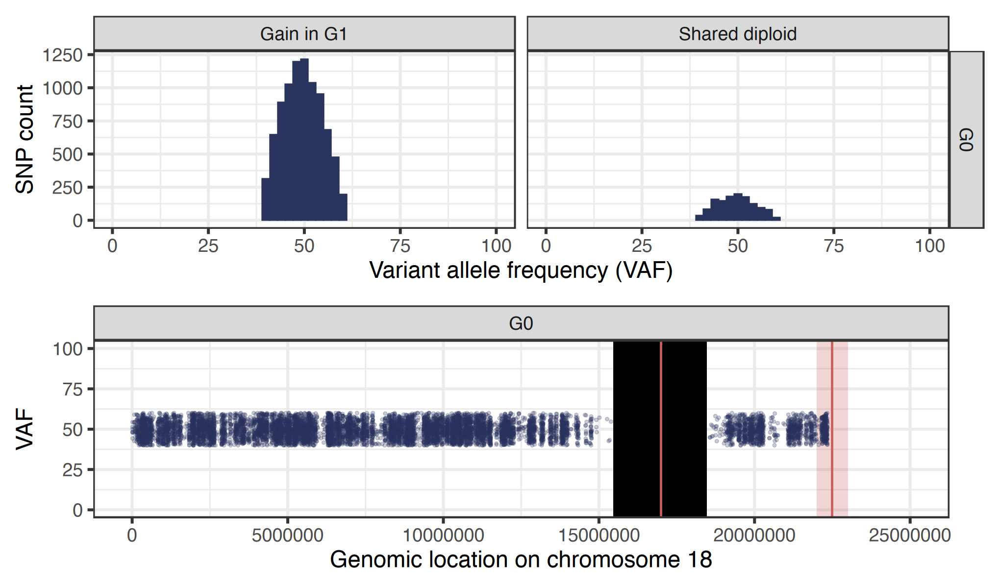

In [74]:
# VAF by genomic position
p1 <- ggplot()+
  geom_rect(aes(xmin=22500000-500000, xmax=22500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G0",], aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.25, size = 1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(xintercept = 22500000, colour = "indianred", linewidth = 1)+
  geom_rect(aes(xmin=15460899, xmax=18460898, ymin=-Inf, ymax=Inf), # Black-out the centromere 
            fill= "black",
            alpha=1)+
  geom_vline(xintercept = 17000000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,25000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 18")+
  guides(fill="none", color = "none")+
  facet_wrap(vars(Clone), nrow = 2)+
  theme_bw(base_size = 28)

# VAF histograms
counts_all$Region <- factor(counts_all$Region, levels = c("Gain in G1","Shared diploid","Shared loss"))

p2 <- ggplot(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G0",], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)

options(repr.plot.width=17, repr.plot.height=10)

p2 / p1


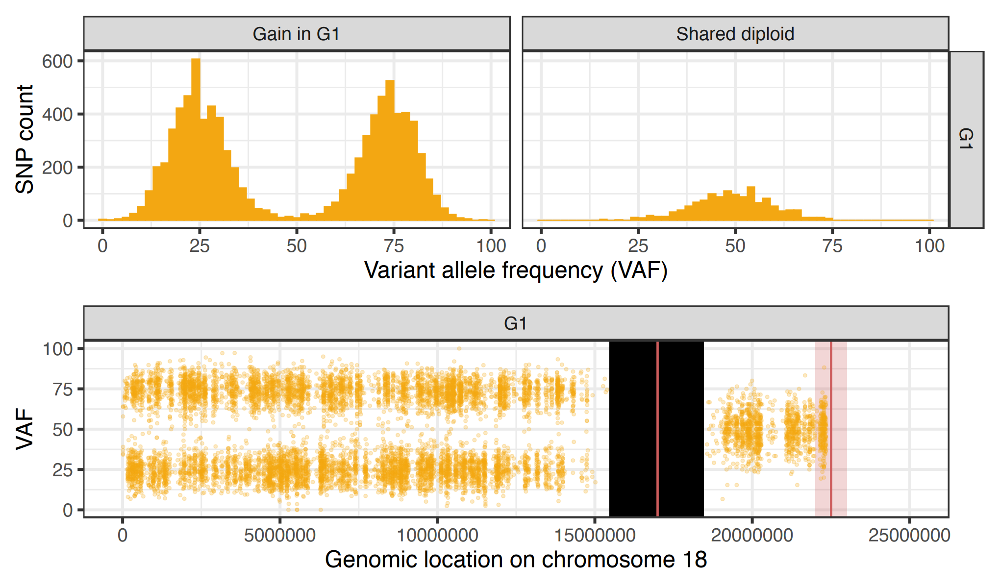

In [75]:
# VAF by genomic position
p1 <- ggplot()+
  geom_rect(aes(xmin=22500000-500000, xmax=22500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G1",], aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.25, size = 1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(xintercept = 22500000, colour = "indianred", linewidth = 1)+
  geom_rect(aes(xmin=15460899, xmax=18460898, ymin=-Inf, ymax=Inf), # Black-out the centromere 
            fill= "black",
            alpha=1)+
  geom_vline(xintercept = 17000000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,25000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 18")+
  guides(fill="none", color = "none")+
  facet_wrap(vars(Clone), nrow = 2)+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region, levels = c("Gain in G1","Shared diploid","Shared loss"))

p2 <- ggplot(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G1",], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1

### ATAC: Compute and compare the heterozygous SNP frequencies in the two copy number clones

In [76]:
atac_snp_18 <- data.frame(atac_snp_fil[grep("18_[0-9]+_[A-Z]_[A-Z]",atac_snp_fil$SNP_ID),])
rownames(atac_snp_18) <- atac_snp_18$SNP_ID


# Filter the SNP matrix to include cells in G0 and G1 
atac_snp_18_cc0 <- atac_snp_18[which(atac_snp_18$SNP_ID %in% counts_18_het_snps),
                             colnames(atac_snp_18) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr18:1000001-13500000" & groups$Altered == "0",]$Clade,]$Cell_id)]
atac_snp_18_cc1 <- atac_snp_18[which(atac_snp_18$SNP_ID %in% counts_18_het_snps),
                             colnames(atac_snp_18) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr18:1000001-13500000" & groups$Altered == "1",]$Clade,]$Cell_id)]

# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
atac_snp_18_cc0 <- atac_snp_18_cc0 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

atac_snp_18_cc1 <- atac_snp_18_cc1 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_a_c0 <- atac_snp_18_cc0[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G0") %>% dplyr::mutate(Mode = "ATAC") %>% 
  mutate(Region = case_when(Location <= 17000000 ~ "Gain in G1",
                            (Location > 17000000 & Location <= 22500000) ~ "Shared diploid",
                            Location > 22500000  ~ "Shared loss")) %>%
  filter((Region == "Gain in G1" & NonNACount >= 4) |
           (Region == "Shared diploid" & NonNACount >= 4) |
           (Region == "Shared loss" & NonNACount >= 2)  )%>%
  left_join(counts_c1[,c("SNP_ID","Allele")], by = "SNP_ID")

counts_a_c1 <- atac_snp_18_cc1[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G1") %>% dplyr::mutate(Mode = "ATAC") %>% 
  mutate(Region = case_when(Location <= 17000000 ~ "Gain in G1",
                            (Location > 17000000 & Location <= 22500000) ~ "Shared diploid",
                            Location > 22500000  ~ "Shared loss")) %>%
  filter((Region == "Gain in G1" & NonNACount >= 8) |
           (Region == "Shared diploid" & NonNACount >= 4) |
           (Region == "Shared loss" & NonNACount >= 2)  ) %>%
  left_join(counts_c1[,c("SNP_ID","Allele")], by = "SNP_ID")



write_csv(counts_a_c0,"../Data/SNP_Data/ATAC/Chr18/Chr18_ATAC_HetSNPs_G0_Info.csv")
write_csv(counts_a_c1,"../Data/SNP_Data/ATAC/Chr18/Chr18_ATAC_HetSNPs_G1_Info.csv")


counts_all <- rbind(counts_a_c0,counts_a_c1) 

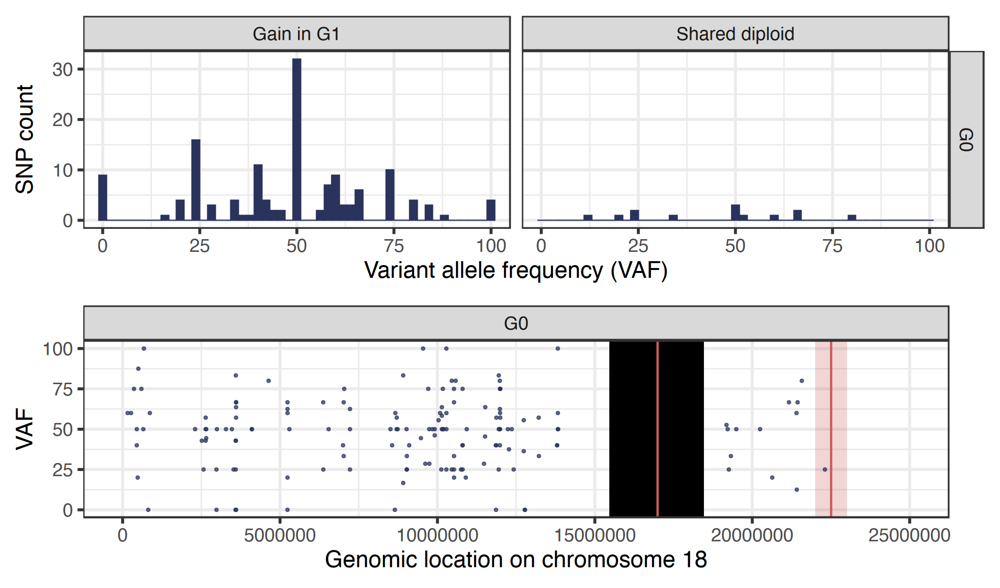

In [77]:
# VAF by genomic position
p1 <- ggplot()+
  geom_rect(aes(xmin=22500000-500000, xmax=22500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[counts_all$Clone == "G0" ,],
             aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.75, size =1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(xintercept = 22500000, colour = "indianred", linewidth = 1)+
  geom_rect(aes(xmin=15460899, xmax=18460898, ymin=-Inf, ymax=Inf), # Black-out the centromere 
            fill= "black",
            alpha=1)+
  geom_vline(xintercept = 17000000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,25000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 18")+
  guides(fill="none", color = "none")+
  facet_wrap(vars(Clone), nrow = 2)+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region,levels = c("Gain in G1","Shared diploid","Shared loss"))

p2 <- ggplot(data = counts_all[ counts_all$Clone == "G0",], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1

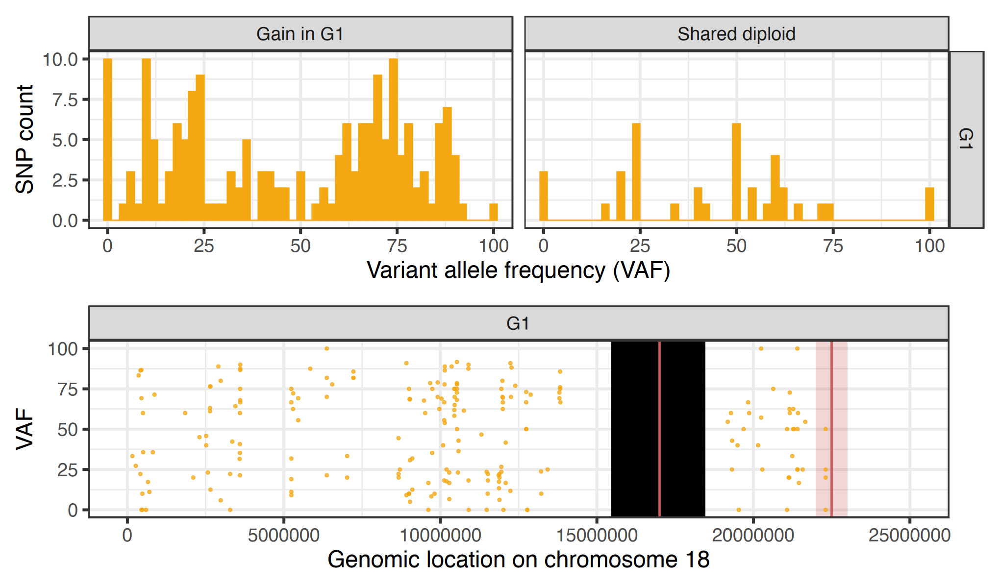

In [78]:
# VAF by genomic position
p1 <- ggplot()+
  geom_rect(aes(xmin=22500000-500000, xmax=22500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[ counts_all$Clone == "G1" ,], aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.75, size =1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(xintercept = 22500000, colour = "indianred", linewidth = 1)+
  geom_rect(aes(xmin=15460899, xmax=18460898, ymin=-Inf, ymax=Inf), # Black-out the centromere 
            fill= "black",
            alpha=1)+
  geom_vline(xintercept = 17000000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,25000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 18")+
  facet_wrap(vars(Clone), nrow = 2)+
  guides(fill="none", color = "none")+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region,levels = c("Gain in G1","Shared diploid","Shared loss"))

p2 <- ggplot(data = counts_all[counts_all$Clone == "G1",], aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1

### Comparing WGS and ATAC VAFs

Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
`geom_smooth()` using formula = 'y ~ x'


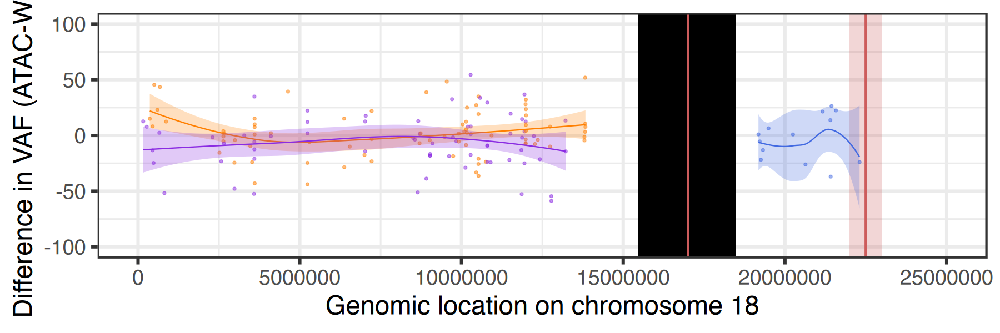

In [79]:
# 1. G0
#counts_a_c0 <- counts_a_c0 %>% dplyr::rename(SNP_ID = SNP_ID)
sameSNPs <- intersect(counts_c0$SNP_ID,counts_a_c0$SNP_ID)

counts_c0_fil <- counts_c0[counts_c0$SNP_ID %in% sameSNPs,]
counts_c0_fil <- counts_c0_fil[order(counts_c0_fil$Location),]

counts_a_c0_fil <- counts_a_c0[counts_a_c0$SNP_ID %in% sameSNPs,]
counts_a_c0_fil <- counts_a_c0_fil[order(counts_a_c0_fil$Location),]

counts_c0_fil$Diff <- -(counts_c0_fil$VariantFreq-counts_a_c0_fil$VariantFreq)
counts_c0_fil$VariantFreq_ATAC <- counts_a_c0_fil$VariantFreq

counts_c0_fil <- counts_c0_fil %>% dplyr::rename(VariantFreq_WGS = VariantFreq) %>%
  mutate(Region = case_when(Location <= 17000000 ~ "Gain in G1",
                            (Location > 17000000 & Location <= 22500000) ~ "Shared diploid",
                            Location > 22500000  ~ "Shared loss"))

counts_c0_fil$Region <- factor(counts_c0_fil$Region,levels = c("Gain in G1","Shared diploid","Shared loss"))

clone_df <- distinct(counts_c0_fil, Clone)

p1 <- ggplot()+
  geom_rect(data = clone_df,
            aes(xmin=22500000-500000, xmax=22500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(aes(xmin=15460899, xmax=18460898, ymin=-Inf, ymax=Inf), # Black-out the centromere 
            fill= "black",
            alpha=1)+
  geom_point(data = counts_c0_fil, aes(x = Location, y = Diff, color = Allele, fill = Allele),alpha = 0.5, size = 1)+
  geom_smooth(data = counts_c0_fil,
              aes(x = Location, y = Diff, color = Allele, fill = Allele),
              method = "loess",span = 1, alpha = 0.25, linewidth = 0.5)+
  scale_color_manual(name = "Allele",
                     values = c("Duplicated allele"="darkorange1",
                                "Non-duplicated allele" = "blueviolet",
                                "Unknown" = "royalblue"))+
  scale_fill_manual(name = "Allele",
                    values = c("Duplicated allele"="darkorange1",
                               "Non-duplicated allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  geom_vline(data = clone_df,xintercept = 17000000, colour = "indianred", linewidth = 1)+
  geom_vline(data = clone_df,xintercept = 22500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(-100,100), xlim = c(1,25000000))+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 18")+
  guides(fill = "none", color = "none" )+
  theme_bw(base_size = 28)

options(repr.plot.width=15, repr.plot.height=5)
p1

Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


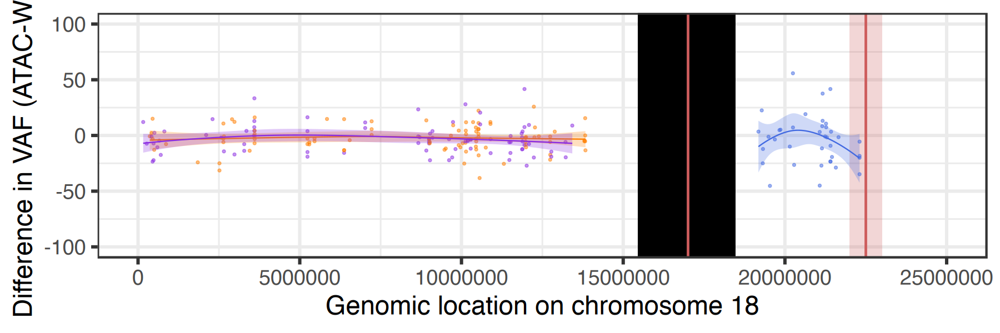

In [80]:
# 2. G1
counts_a_c1 <- counts_a_c1 %>% dplyr::rename(SNP_ID = SNP_ID)
sameSNPs <- intersect(counts_a_c1$SNP_ID,counts_c1$SNP_ID)

counts_c1_fil <- counts_c1[counts_c1$SNP_ID %in% sameSNPs,]
counts_c1_fil <- counts_c1_fil[order(counts_c1_fil$Location),]

counts_a_c1_fil <- counts_a_c1[counts_a_c1$SNP_ID %in% sameSNPs,]
counts_a_c1_fil <- counts_a_c1_fil[order(counts_a_c1_fil$Location),]

counts_c1_fil$Diff <- (counts_a_c1_fil$VariantFreq-counts_c1_fil$VariantFreq)
counts_c1_fil$VariantFreq_ATAC <- counts_a_c1_fil$VariantFreq

counts_c1_fil <- counts_c1_fil %>% dplyr::rename(VariantFreq_WGS = VariantFreq) %>% 
  mutate(Region = case_when(Location <= 17000000 ~ "Gain in G1",
                            (Location > 17000000 & Location <= 22500000) ~ "Shared diploid",
                            Location > 22500000  ~ "Shared loss"))

counts_c1_fil$Region <- factor(counts_c1_fil$Region,levels =c("Gain in G1","Shared diploid","Shared loss"))
clone_df <- distinct(counts_c1_fil, Clone)

p2 <- ggplot()+
  geom_rect(data = clone_df,
            aes(xmin=22500000-500000, xmax=22500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_rect(aes(xmin=15460899, xmax=18460898, ymin=-Inf, ymax=Inf), # Black-out the centromere 
            fill= "black",
            alpha=1)+
  geom_point(data = counts_c1_fil, aes(x = Location, y = Diff, color = Allele,
                                       fill= Allele),alpha = 0.5, size = 1)+
  geom_smooth(data = counts_c1_fil[counts_c1_fil$Region == "Gain in G1",],aes(x = Location, 
                                                                                         y = Diff, 
                                                                                         color = Allele,
                                                                                         fill= Allele),
              method = "loess",span = 1, alpha = 0.25, linewidth = 0.5)+
  geom_smooth(data = counts_c1_fil[counts_c1_fil$Region == "Shared diploid",],aes(x = Location, 
                                                                                          y = Diff, 
                                                                                          color = Allele,
                                                                                          fill= Allele),
              method = "loess",span = 1, alpha = 0.25, linewidth = 0.5)+
  scale_color_manual(name = "Allele",
                     values = c("Duplicated allele"="darkorange1",
                                "Non-duplicated allele" = "blueviolet",
                                "Unknown" = "royalblue"))+
  scale_fill_manual(name = "Allele",
                    values = c("Duplicated allele"="darkorange1",
                               "Non-duplicated allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  geom_vline(data = clone_df,xintercept = 17000000, colour = "indianred", linewidth = 1)+
  geom_vline(data = clone_df,xintercept = 22500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(-100,100), xlim = c(1,25000000))+
  guides(fill = "none", color = "none" )+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 18")+
  theme_bw(base_size = 28)

options(repr.plot.width=15, repr.plot.height=5)
p2

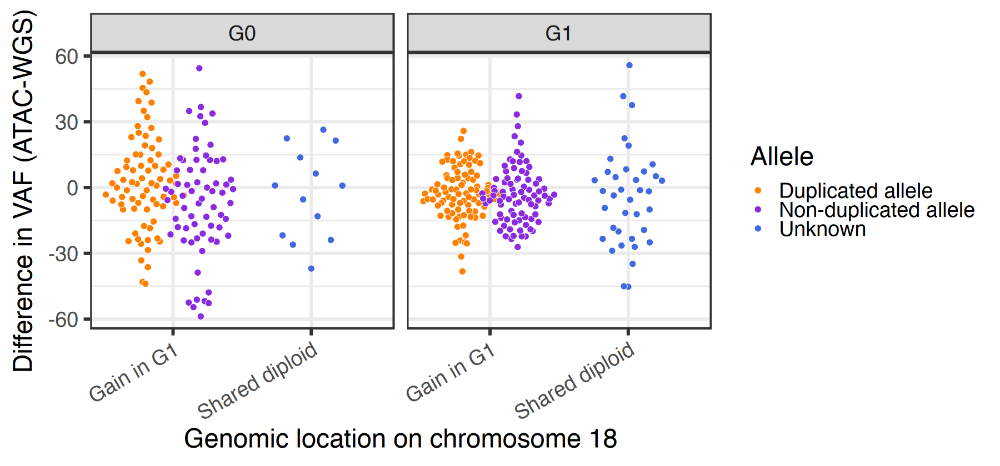

In [82]:
# 3. G0 and G1 
counts_a_fil <- rbind(counts_c0_fil,counts_c1_fil)

counts_a_fil$Region <- factor(counts_a_fil$Region,levels = c("Gain in G1","Shared diploid","Shared loss"))


p <- ggplot(data = counts_a_fil, aes(x = Region, y = Diff, color = Allele, fill = Allele))+
  #geom_point(data = counts_a_filb, aes(x = Region, y = Diff, color = Allele, fill = Allele),
  #           alpha = 0.5)+
  #geom_violin(alpha = 0.10, width = 0.9, position = position_dodge(width=1), linewidth = 0.5)+
  #geom_boxplot(alpha = 0.25, width = 0.3, position = position_dodge(width=1), linewidth = 0.5)+
  geom_quasirandom(
    dodge.width = 0.8,
    shape = 21,
    color = "white",
    alpha = 1,
    size = 3,
    stroke = 0.3,
    width = 0.3,         # how wide the cloud is
    varwidth = TRUE      # makes the dots follow density (violin shape)
  )+
  scale_fill_manual(name = "Allele",
                    values = c("Duplicated allele"="darkorange1",
                               "Non-duplicated allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 18")+
  facet_wrap(vars(Clone),nrow = 1)+
  theme_bw(base_size = 28)+
    theme(
        axis.text.x = element_text(angle = 30, hjust = 1)
    )

options(repr.plot.width=15, repr.plot.height=7)
p

## Gain in chromosome 20

### WGS: Identify heterozygous SNPs

In [90]:
# Select for the SNPs on chromsome 20
wgs_snp_20 <- data.frame(wgs_snp[grep("20_[0-9]+_[A-Z]_[A-Z]",wgs_snp$SNP_ID),])
rownames(wgs_snp_20) <- wgs_snp_20$SNP_ID

# Identify the heterozygous SNPs using the cells which are diploid in the region
# 1-40 Mb

# Select for those cells
wgs_snp_20_dip <- wgs_snp_20[,colnames(wgs_snp_20) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr20:500001-19500000" & groups$Altered == "0",]$Clade,]$Cell_id)] 

# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
wgs_snp_20_dip <- wgs_snp_20_dip %>% dplyr::mutate(Present = rowSums(across(everything(), ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(everything(), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(everything(), ~ .x == -1)))

counts_20_dip <- wgs_snp_20_dip[,c("SNP_ID","Present","Absent","NA")]

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_20_dip <- counts_20_dip %>% dplyr::mutate(VariantFreq =100*(Present/(Absent + Present))) %>% 
  dplyr::mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(unlist(str_split(counts_20_dip$SNP_ID,"_"))[seq(2,nrow(counts_20_dip)*4,4)])) %>%
  mutate(Region = case_when(Location <= 17500000 ~ "Gain in G1",
                            Location > 17500000 ~ "Shared gain"))

# Save the SNP info
write_csv(counts_20_dip, "../Data/SNP_Data/WGS/Chr20/Chr20_WGS_AllSNPs_Info.csv")

# Filter for heterozygous SNPs, which have at least 10 support reads 
# (i.e., 10 cells with the SNP)
counts_20_het <- counts_20_dip %>% filter( ( VariantFreq >= 23 & VariantFreq <= 43) | 
                                             ( VariantFreq >= 56 & VariantFreq <= 76)) %>% 
  filter(Present >= 10)


# heterozygous SNP ids
counts_20_het_snps <- counts_20_het$SNP_ID

# Save the heterozygous SNP info
write_csv(counts_20_het, "../Data/SNP_Data/WGS/Chr20/Chr20_WGS_HetSNPs_Info.csv")


### Compute and compare the heterozygous SNP frequencies in the two copy number clones

In [93]:
### COmpute SNP vafs
# Filter the SNP matrix to include cells in G0 and CG 
wgs_snp_20_cc0 <- wgs_snp_20[rownames(wgs_snp_20) %in% counts_20_het_snps,
                             colnames(wgs_snp_20) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr20:500001-19500000" & groups$Altered == "0",]$Clade ,]$Cell_id)]
wgs_snp_20_cc1 <- wgs_snp_20[rownames(wgs_snp_20) %in% counts_20_het_snps,
                             colnames(wgs_snp_20) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr20:500001-19500000" & groups$Altered == "1",]$Clade,]$Cell_id)]

#
# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
wgs_snp_20_cc0 <- wgs_snp_20_cc0 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

wgs_snp_20_cc1 <- wgs_snp_20_cc1 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_c0 <- wgs_snp_20_cc0[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G0") %>% dplyr::mutate(Mode = "WGS") %>% 
  mutate(Region = case_when(Location <= 17500000 ~ "Gain in G1",
                            Location > 17500000 ~ "Shared gain"))


counts_c1 <- wgs_snp_20_cc1[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G1") %>% dplyr::mutate(Mode = "WGS") %>% 
  mutate(Region = case_when(Location <= 17500000 ~ "Gain in G1",
                            Location > 17500000 ~ "Shared gain"))



# Filter for SNPs with at least 2 reads per allele (on average)
counts_c0 <- counts_c0 %>% filter(NonNACount >= 6)
counts_c1 <- counts_c1 %>%
  filter((Region == "Gain in G1" & NonNACount >= 8) |
           (Region == "Shared gain" & NonNACount >= 6))

# Define whether SNPs are in open or closed chromatin 
# (based on ATAC signal in peaks computed for each clone)

# Peaks with positions defined in hg38
peaks_hg38 <- read_csv("../Data/ATAC_Data/PeakData/Chr20/Chr20Gain_PeakInformation.csv", col_types = "ccddccc")

# Peaks in each clone with positions defined in hg38
peaks_hg38_c0 <- read_csv("../Data/ATAC_Data/PeakData/Chr20/Chr20Gain_PeakScores_G0.csv", col_types = "cdd")
peaks_hg38_c1 <- read_csv("../Data/ATAC_Data/PeakData/Chr20/Chr20Gain_PeakScores_G1.csv", col_types = "cdd")

# Create text files with the peak position for liftover
gr_c0 <- GRanges(
  seqnames = peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c0$Peak_ID,]$chrom,
  ranges = IRanges(peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c0$Peak_ID,]$start,
                   peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c0$Peak_ID,]$end))

ch = rtracklayer::import.chain("../Data/SNP_Data/hg38ToHg19.over.chain")


gr_c0_19 <- data.frame(unlist(liftOver(gr_c0, ch)))

gr_c1 <- GRanges(
  seqnames = peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c1$Peak_ID,]$chrom,
  ranges = IRanges(peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c1$Peak_ID,]$start,
                   peaks_hg38[peaks_hg38$ID %in% peaks_hg38_c1$Peak_ID,]$end))


gr_c1_19 <- data.frame(unlist(liftOver(gr_c1, ch)))



# Perform liftover in UCSC Genome Browser (https://genome.ucsc.edu/cgi-bin/hgLiftOver

counts_20_het_snps_location <- as.numeric(unlist(str_split(counts_20_het_snps,"_"))[seq(2,length(counts_20_het_snps)*4,4)])

heterozygous_snps_open_c0 <- c()
for (i in 1:length(counts_20_het_snps)){
  ind <- which(gr_c0_19$start <= counts_20_het_snps_location[i] & gr_c0_19$end >= counts_20_het_snps_location[i])
  if (length(ind) == 0){
    next
  } else {
    heterozygous_snps_open_c0 <- c(heterozygous_snps_open_c0, counts_20_het_snps[i])
  }
}

heterozygous_snps_open_c1 <- c()
for (i in 1:length(counts_20_het_snps)){
  ind <- which(gr_c1_19$start <= counts_20_het_snps_location[i] & gr_c1_19$end >= counts_20_het_snps_location[i])
  if (length(ind) == 0){
    next
  }else {
    heterozygous_snps_open_c1 <- c(heterozygous_snps_open_c1, counts_20_het_snps[i])
  }
}

counts_c0 <- counts_c0 %>% mutate("Chromatin state" = case_when(SNP_ID %in% heterozygous_snps_open_c0 ~ "Open",
                                                                .default = "Closed")) %>%
  mutate(Allele = case_when(VariantFreq < 50 ~ "Non-duplicated allele",
                            VariantFreq > 50 ~ "Duplicated allele"))

counts_c1 <- counts_c1 %>% mutate("Chromatin state" = case_when(SNP_ID %in% heterozygous_snps_open_c1 ~ "Open",
                                                                .default = "Closed")) %>%
  left_join(counts_c0[,c("SNP_ID","Allele")], by = "SNP_ID")



write_csv(counts_c0,"../Data/SNP_Data/WGS/Chr20/Chr20_WGS_HetSNPs_G0_Info.csv")
write_csv(counts_c1,"../Data/SNP_Data/WGS/Chr20/Chr20_WGS_HetSNPs_G1_Info.csv")

# Combine G0 and CG SNP VAFs into one dataframe
counts_all <- rbind(counts_c0,counts_c1) 
write_csv(counts_all,"../Data/SNP_Data/WGS/Chr20/Chr20_WGS_HetSNPs_G0AndG1_Info.csv")

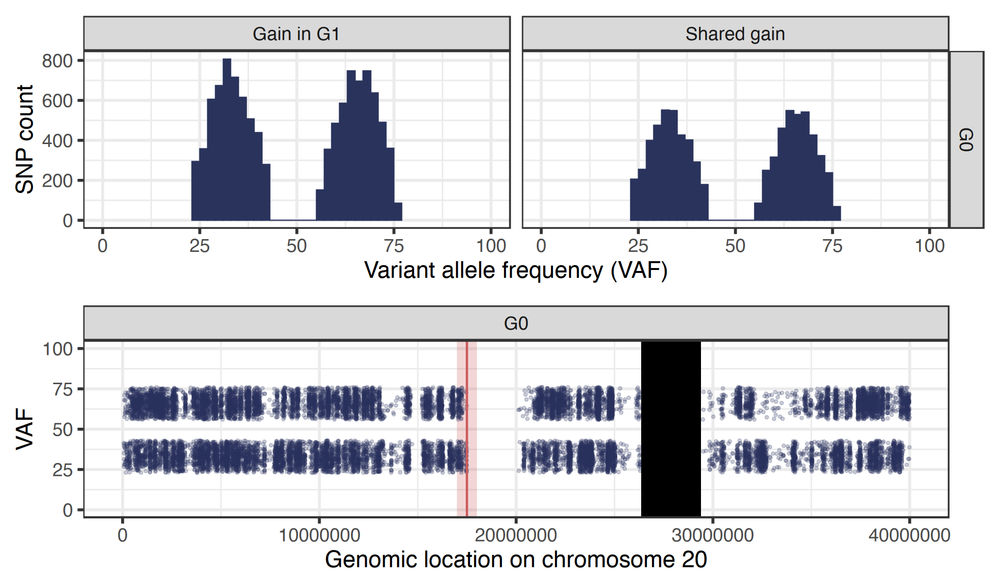

In [94]:
p1 <- ggplot()+
  geom_rect(aes(xmin=17500000-500000, xmax=17500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G0"&
                                (counts_all$Location < 17500000 | counts_all$Location > 20000000),],
             aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.25, size = 1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_rect(aes(xmin=26369569, xmax=29369569, ymin=-Inf, ymax=Inf), # Black-out the centromere 
            fill= "black",
            alpha=1)+
  geom_vline(xintercept = 17500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,40000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 20")+
  guides(fill="none", color = "none")+
  facet_wrap(vars(Clone), nrow = 2)+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region, levels = c("Gain in G1","Shared gain"))

p2 <- ggplot(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G0" &
                                 (counts_all$Location < 17500000 | counts_all$Location > 20000000),],
             aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1

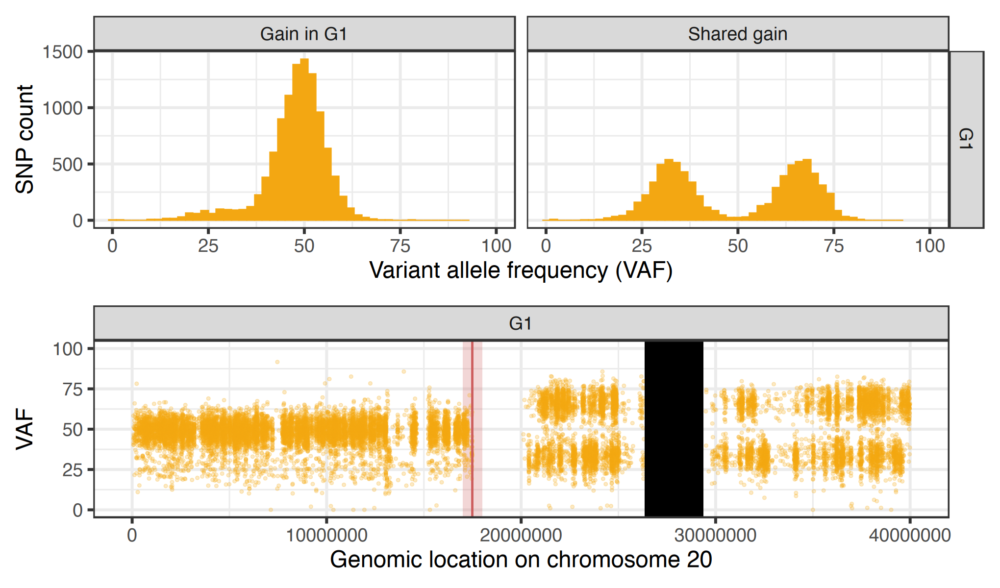

In [97]:
# VAF by genomic position
p1 <- ggplot()+
  geom_rect(aes(xmin=17500000-500000, xmax=17500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G1"&
                                 (counts_all$Location < 17500000 | counts_all$Location > 20000000),],
             aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.25, size = 1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_rect(aes(xmin=26369569, xmax=29369569, ymin=-Inf, ymax=Inf), # Black-out the centromere 
            fill= "black",
            alpha=1)+
  geom_vline(xintercept = 17500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,40000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 20")+
  guides(fill="none", color = "none")+
  facet_wrap(vars(Clone), nrow = 2)+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region, levels = c("Gain in G1","Shared gain"))

p2 <- ggplot(data = counts_all[counts_all$NonNACount > 0 &
                                 counts_all$Clone == "G1"&
                                 (counts_all$Location < 17500000 | counts_all$Location > 20000000),],
             aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)
p2 / p1

### ATAC: Compute and compare the heterozygous SNP frequencies in the two copy number clones

In [99]:
atac_snp_20 <- data.frame(atac_snp_fil[grep("20_[0-9]+_[A-Z]_[A-Z]",atac_snp_fil$SNP_ID),])
rownames(atac_snp_20) <- atac_snp_20$SNP_ID


# Filter the SNP matrix to include cells in G0 and G1 
atac_snp_20_cc0 <- atac_snp_20[which(atac_snp_20$SNP_ID %in% counts_20_het_snps),
                               colnames(atac_snp_20) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr20:500001-19500000" & groups$Altered == "0",]$Clade,]$Cell_id)]
atac_snp_20_cc1 <- atac_snp_20[which(atac_snp_20$SNP_ID %in% counts_20_het_snps),
                               colnames(atac_snp_20) %in% c("SNP_ID",clades[clades$Clade %in% groups[groups$Location == "chr20:500001-19500000" & groups$Altered == "1",]$Clade,]$Cell_id)]

# Count the number of cells with and without the SNP, as well as the number of cells
# with no read at the SNP position
atac_snp_20_cc0 <- atac_snp_20_cc0 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

atac_snp_20_cc1 <- atac_snp_20_cc1 %>% dplyr::mutate(Present = rowSums(across(-SNP_ID, ~ .x == 1))) %>%
  dplyr::mutate(Absent = rowSums(across(-c(SNP_ID,Present), ~ .x == 0))) %>% 
  dplyr::mutate("NA" = rowSums(across(-c(SNP_ID,Present,Absent), ~ .x == -1)))

# Define the VAFs, number of reads per SNPs, SNP location and corresponding region
counts_a_c0 <- atac_snp_20_cc0[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G0") %>% dplyr::mutate(Mode = "ATAC") %>% 
  mutate(Region = case_when(Location <= 17500000 ~ "Gain in G1",
                            Location > 17500000 ~ "Shared gain")) %>%
  filter((Region == "Gain in G1" & NonNACount >= 6) |
           (Region == "Shared gain" & NonNACount >= 6)  ) %>%
  left_join(counts_c0[,c("SNP_ID","Allele")], by = "SNP_ID")

counts_a_c1 <- atac_snp_20_cc1[,c("SNP_ID","Present","Absent","NA")] %>% dplyr::mutate(VariantFreq = 100*(Present/(Absent + Present))) %>%
  mutate(NonNACount = (Absent + Present)) %>%
  mutate(Location = as.numeric(str_split(SNP_ID,"_",simplify = T)[,2])) %>% 
  mutate(Clone = "G1") %>% dplyr::mutate(Mode = "ATAC") %>% 
  mutate(Region = case_when(Location <= 17500000 ~ "Gain in G1",
                            Location > 17500000 ~ "Shared gain")) %>%
  filter((Region == "Gain in G1" & NonNACount >= 8) |
           (Region == "Shared gain" & NonNACount >= 6)  ) %>%
  left_join(counts_c0[,c("SNP_ID","Allele")], by = "SNP_ID")


write_csv(counts_a_c0,"../Data/SNP_Data/ATAC/Chr20/Chr20_ATAC_HetSNPs_G0_Info_17-12-25.csv")
write_csv(counts_a_c1,"../Data/SNP_Data/ATAC/Chr20/Chr20_ATAC_HetSNPs_G1_Info_17-12-25.csv")


counts_all <- rbind(counts_a_c0,counts_a_c1) 

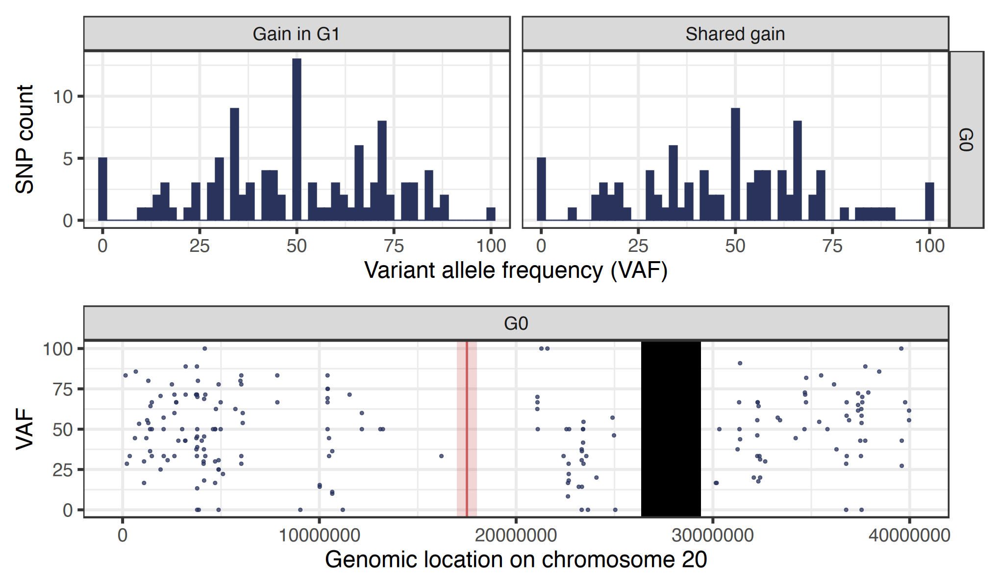

In [100]:
# VAF by genomic position
p1 <- ggplot()+
  geom_rect(aes(xmin=17500000-500000, xmax=17500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[counts_all$Clone == "G0" &
                                 (counts_all$Location < 17500000 |counts_all$Location > 20000000),],
             aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.75, size =1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_vline(xintercept = 17500000, colour = "indianred", linewidth = 1)+
  geom_rect(aes(xmin=26369569, xmax=29369569, ymin=-Inf, ymax=Inf), # Black-out the centromere 
            fill= "black",
            alpha=1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,40000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 20")+
  guides(fill="none", color = "none")+
  facet_wrap(vars(Clone), nrow = 2)+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region,levels = c("Gain in G1","Shared gain"))

p2 <- ggplot(data = counts_all[ counts_all$Clone == "G0" &
                                  (counts_all$Location < 17500000 |counts_all$Location > 20000000),],
             aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1


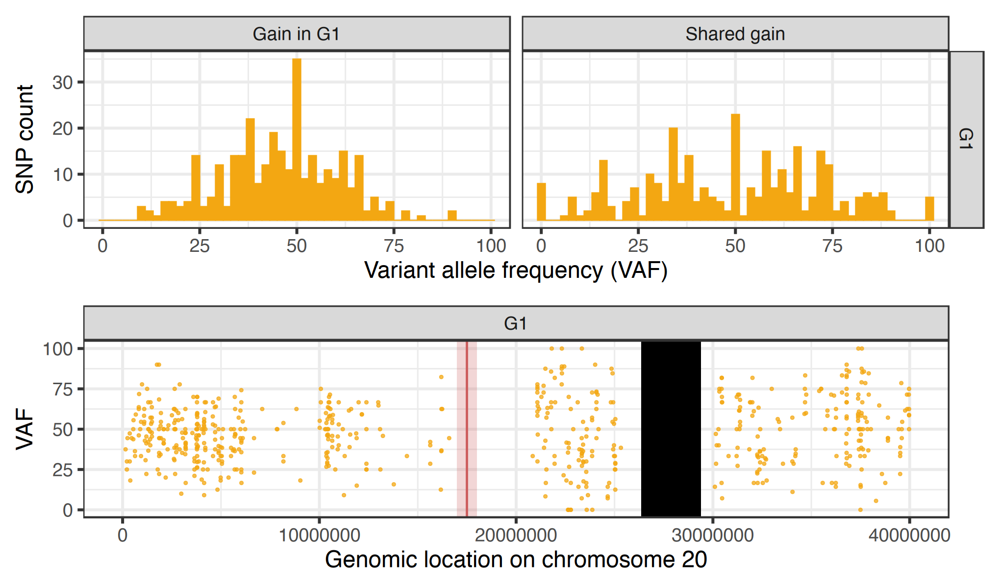

In [101]:
# VAF by genomic position
p1 <- ggplot()+
  geom_rect(aes(xmin=17500000-500000, xmax=17500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_all[ counts_all$Clone == "G1" &
                                  (counts_all$Location < 17500000 |counts_all$Location > 20000000),],
             aes(x = Location, y = VariantFreq, group = Clone, color = Clone),
             alpha = 0.75, size =1.5)+
  scale_colour_manual(name = "Clone",
                      values = c("G0" = "#29335c","G1"="#f3a712"))+
  geom_rect(aes(xmin=26369569, xmax=29369569, ymin=-Inf, ymax=Inf), # Black-out the centromere 
            fill= "black",
            alpha=1)+
  geom_vline(xintercept = 17500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(0,100), xlim = c(1,40000000))+
  ylab("VAF") +
  xlab("Genomic location on chromosome 20")+
  facet_wrap(vars(Clone), nrow = 2)+
  guides(fill="none", color = "none")+
  theme_bw(base_size = 28)


# VAF histograms
counts_all$Region <- factor(counts_all$Region,levels = c("Gain in G1","Shared gain"))

p2 <- ggplot(data = counts_all[counts_all$Clone == "G1"&
                                 (counts_all$Location < 17500000 |counts_all$Location > 20000000),],
             aes(x = VariantFreq, group = Clone, fill = Clone, color = Clone))+
  geom_histogram(binwidth = 2)+
  scale_fill_manual(name = "Clone",
                    values = c("G0" = "#29335c","G1"="#f3a712"))+
  scale_color_manual(name = "Clone",
                     values = c("G0" = "#29335c","G1"="#f3a712"))+
  ylab("SNP count") +
  xlab("Variant allele frequency (VAF)")+
  coord_cartesian(xlim = c(0,100))+
  guides(fill="none", color = "none")+
  facet_grid(rows = vars(Clone), cols = vars(Region))+
  theme_bw(base_size = 28)


options(repr.plot.width=17, repr.plot.height=10)

p2 / p1

### Comparing WGS and ATAC VAFs

Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
`geom_smooth()` using formula = 'y ~ x'


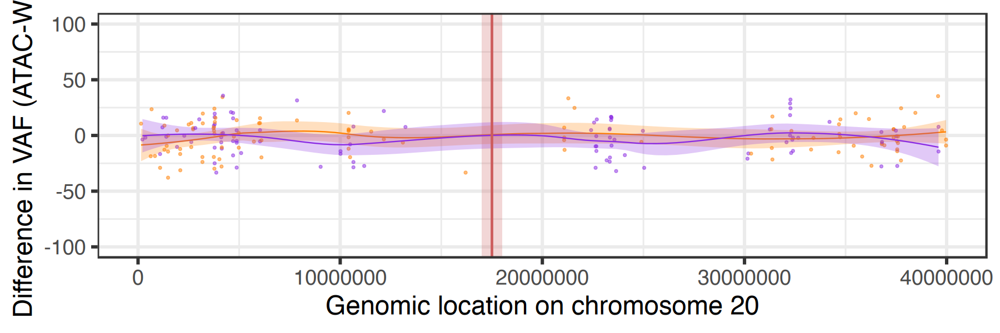

In [103]:
# 1. G0
#counts_a_c0 <- counts_a_c0 %>% dplyr::rename(SNP_ID = SNP_ID)
sameSNPs <- intersect(counts_c0$SNP_ID,counts_a_c0$SNP_ID)

counts_c0_fil <- counts_c0[counts_c0$SNP_ID %in% sameSNPs,]
counts_c0_fil <- counts_c0_fil[order(counts_c0_fil$Location),]

counts_a_c0_fil <- counts_a_c0[counts_a_c0$SNP_ID %in% sameSNPs,]
counts_a_c0_fil <- counts_a_c0_fil[order(counts_a_c0_fil$Location),]

counts_c0_fil$Diff <- -(counts_c0_fil$VariantFreq-counts_a_c0_fil$VariantFreq)
counts_c0_fil$VariantFreq_ATAC <- counts_a_c0_fil$VariantFreq

counts_c0_fil <- counts_c0_fil %>% dplyr::rename(VariantFreq_WGS = VariantFreq) %>%
  #dplyr::mutate(Allele = case_when(VariantFreq_WGS > 50 ~ "Duplicated allele", 
  #                                 VariantFreq_WGS < 50 ~ "Non-duplicated allele")) %>%
  mutate(Region = case_when(Location <= 17500000 ~ "Gain in G1",
                            Location > 17500000  ~ "Shared gain"))

counts_c0_fil$Region <- factor(counts_c0_fil$Region,levels = c("Gain in G1","Shared gain"))
clone_df <- distinct(counts_c0_fil, Clone)

p1 <- ggplot()+
  geom_rect(data = clone_df,
            aes(xmin=17500000-500000, xmax=17500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_c0_fil[counts_c0_fil$Location < 17500000 | counts_c0_fil$Location  > 20000000,], aes(x = Location, y = Diff, color = Allele, fill = Allele),
             alpha = 0.5, size = 1)+
  geom_smooth(data = counts_c0_fil,
              aes(x = Location, y = Diff, color = Allele, fill = Allele),
              method = "loess",span = 0.5, alpha = 0.25, linewidth = 0.5)+
  scale_color_manual(name = "Allele",
                     values = c("Duplicated allele"="darkorange1",
                                "Non-duplicated allele" = "blueviolet",
                                "Unknown" = "royalblue"))+
  scale_fill_manual(name = "Allele",
                    values = c("Duplicated allele"="darkorange1",
                               "Non-duplicated allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  geom_vline(data = clone_df, xintercept = 17500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(-100,100), xlim = c(1,40000000))+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 20")+
  guides(fill = "none", color = "none")+
  theme_bw(base_size = 28)

options(repr.plot.width=15, repr.plot.height=5)
p1

Warning message:
“`geom_vline()`: Ignoring `data` because `xintercept` was provided.”
`geom_smooth()` using formula = 'y ~ x'


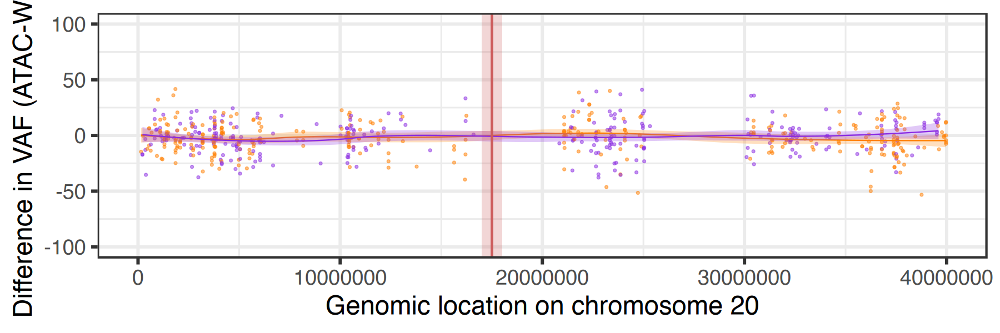

In [104]:
# 2. G1
counts_a_c1 <- counts_a_c1 %>% dplyr::rename(SNP_ID = SNP_ID)
sameSNPs <- intersect(counts_a_c1$SNP_ID,counts_c1$SNP_ID)

counts_c1_fil <- counts_c1[counts_c1$SNP_ID %in% sameSNPs,]
counts_c1_fil <- counts_c1_fil[order(counts_c1_fil$Location),]

counts_a_c1_fil <- counts_a_c1[counts_a_c1$SNP_ID %in% sameSNPs,]
counts_a_c1_fil <- counts_a_c1_fil[order(counts_a_c1_fil$Location),]

counts_c1_fil$Diff <- (counts_a_c1_fil$VariantFreq-counts_c1_fil$VariantFreq)
counts_c1_fil$VariantFreq_ATAC <- counts_a_c1_fil$VariantFreq


counts_c1_fil <- counts_c1_fil %>% dplyr::rename(VariantFreq_WGS = VariantFreq) %>% 
  #dplyr::mutate(Allele = case_when(Location > 17500000  & VariantFreq_WGS > 50 ~ "Duplicated allele", 
  #                                 Location > 17500000  & VariantFreq_WGS < 50 ~ "Non-duplicated allele", 
  #                                 Location <= 17500000  ~ "Unknown")) %>% 
  mutate(Region = case_when(Location <= 17500000 ~ "Gain in G1",
                            Location > 17500000 ~ "Shared gain"))

counts_c1_fil$Region <- factor(counts_c1_fil$Region,levels =c("Gain in G1","Shared gain"))
clone_df <- distinct(counts_c1_fil, Clone)

p2 <- ggplot()+
  geom_rect(data = clone_df,
            aes(xmin=17500000-500000, xmax=17500000+500000, ymin=-Inf, ymax=Inf),
            fill = "indianred",
            alpha = 0.25)+
  geom_point(data = counts_c1_fil[counts_c1_fil$Location < 17500000 | counts_c1_fil$Location > 20000000,], 
             aes(x = Location, y = Diff, color = Allele,
                 fill= Allele),
             alpha = 0.5, size = 1)+
  geom_smooth(data = counts_c1_fil,aes(x = Location, 
                                                                              y = Diff, 
                                                                              color = Allele,
                                                                              fill= Allele),
              method = "loess",span = 0.5, alpha = 0.25, linewidth = 0.5)+
  scale_color_manual(name = "Allele",
                     values = c("Duplicated allele"="darkorange1",
                                "Non-duplicated allele" = "blueviolet",
                                "Unknown" = "royalblue"))+
  scale_fill_manual(name = "Allele",
                    values = c("Duplicated allele"="darkorange1",
                               "Non-duplicated allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  geom_vline(data = clone_df,xintercept = 17500000, colour = "indianred", linewidth = 1)+
  coord_cartesian(ylim = c(-100,100), xlim = c(1,40000000))+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 20")+
  guides(fill = "none", color = "none")+
  theme_bw(base_size = 28)

options(repr.plot.width=15, repr.plot.height=5)
p2

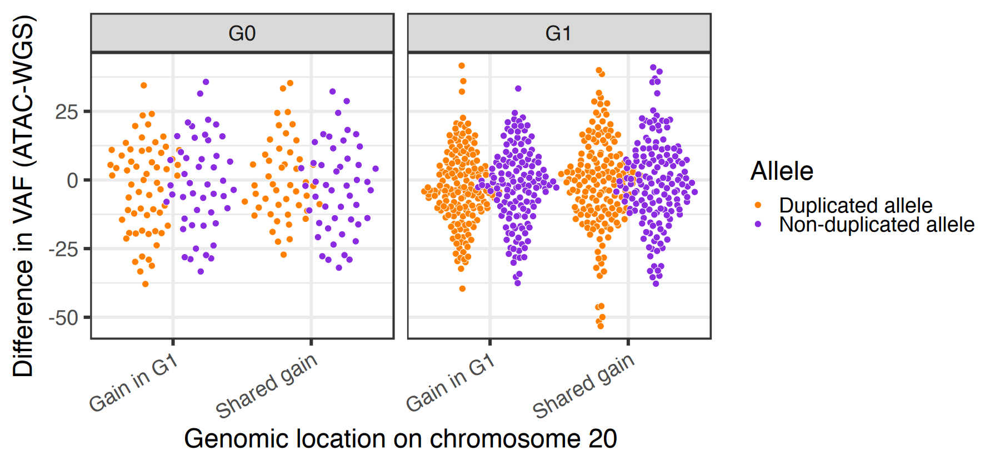

In [105]:
# 3. G0 and G1 
counts_a_fil <- rbind(counts_c0_fil,counts_c1_fil)

counts_a_fil$Region <- factor(counts_a_fil$Region,levels = c("Gain in G1","Shared gain"))


p <- ggplot(data = counts_a_fil, aes(x = Region, y = Diff, color = Allele, fill = Allele))+
  #geom_point(data = counts_a_filb, aes(x = Region, y = Diff, color = Allele, fill = Allele),
  #           alpha = 0.5)+
  #geom_violin(alpha = 0.10, width = 0.9, position = position_dodge(width=1), linewidth = 0.5)+
  #geom_boxplot(alpha = 0.25, width = 0.3, position = position_dodge(width=1), linewidth = 0.5)+
  geom_quasirandom(
    dodge.width = 0.8,
    shape = 21,
    color = "white",
    alpha = 1,
    size = 3,
    stroke = 0.3,
    width = 0.3,         # how wide the cloud is
    varwidth = TRUE      # makes the dots follow density (violin shape)
  )+
  scale_fill_manual(name = "Allele",
                    values = c("Duplicated allele"="darkorange1",
                               "Non-duplicated allele" = "blueviolet",
                               "Unknown" = "royalblue"))+
  ylab("Difference in VAF (ATAC-WGS)") +
  xlab("Genomic location on chromosome 20")+
  facet_wrap(vars(Clone),nrow = 1)+
  theme_bw(base_size = 28)+
    theme(
        axis.text.x = element_text(angle = 30, hjust = 1)
    )


options(repr.plot.width=15, repr.plot.height=7)
p